# EDA — IBM AML HI-Small: full file, then the subsample the model is built on

**Data.** IBM's synthetic anti-money-laundering data, HI-Small: ~5M transfers, 1–18 Sept 2022, label
`Is Laundering`. The three Kaggle files are joined by `src/01_join_sql.py` into
`data/processed/hi_small_joined.parquet`. The model is trained on a **subsample** (~750k rows) built by
`src/02_subsample_split.py`.

**Two parts, with different jobs:**

| Part | Data | Job |
|---|---|---|
| **A** (short) | full joined file | Get right what the join, the sampler and the account history depend on: data quality, where the data really ends, what a self-transfer is, how schemes look, bank names, exchange rates, hubs. |
| **B** (main) | time-split subsample | Check the subsample can be trusted and how it must be handled, then study every signal **on the train split, weighted**, and turn each finding into a preprocessing rule. |

Every section ends with **→ Rule**, the decision `03_PREPROCESSING` implements. B19 lists them all.

**How to run.** Put the three raw files in `data/raw/` and run all cells. The notebook builds the joined
file and the subsample itself when they are missing. Plain pandas / numpy; needs ~5 GB of RAM.

**Never a feature:** `Attempt ID` and `Pattern Type` come from the answer key (they exist only for laundering
rows). They are used here to understand schemes, never as model inputs.

## 0. Setup

Loads the joined file **once** (text columns as categories, which keeps memory low) and defines the helpers used everywhere below.

In [1]:
import os
import sys
import subprocess
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)


def find_root():
    """The aml_pipeline folder (the one holding src/). Works from notebooks/ or from the folder itself."""
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "src" / "eda_utils.py").is_file():
            return p
    raise FileNotFoundError("open this notebook from inside the aml_pipeline folder")


ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu  # scheme drawings and the source-file comparison

JOINED = ROOT / "data" / "processed" / "hi_small_joined.parquet"
CUT = pd.Timestamp("2022-09-11")          # the data really ends on 10 Sept (section B1)

# True = rebuild the joined file and the subsample even if they exist (needs the raw files in data/raw).
# False = build them only when missing.
RUN_PIPELINE = False


def run_script(name, *args):
    """Run one pipeline script (in src/) and print the end of its report."""
    r = subprocess.run([sys.executable, str(ROOT / "src" / name), *args], capture_output=True, text=True, cwd=ROOT,
                       encoding="utf-8", errors="replace", env={**os.environ, "PYTHONIOENCODING": "utf-8"})
    print(r.stdout[-4000:])
    if r.returncode:
        print(r.stderr[-2000:])


RAW = ROOT / "data" / "raw"
RAW_FILES = ["HI-Small_Trans.csv", "HI-Small_accounts.csv", "HI-Small_Patterns.txt"]
if RUN_PIPELINE or (not JOINED.exists() and all((RAW / f).exists() for f in RAW_FILES)):
    print("joined file missing -> running src/01_join_sql.py (~1 min)")
    run_script("01_join_sql.py")
if not JOINED.exists():
    raise FileNotFoundError(
        f"Joined file not found at:\n  {JOINED}\n"
        f"Either copy hi_small_joined.parquet there, or put {', '.join(RAW_FILES)} in\n  {RAW}\n"
        "and re-run this cell (it will run the join itself).")

# ------------------------------------------------------------------ loading
# Sender / receiver columns that are compared with each other share one category list.
PAIRS = [("Account", "Account.1"), ("Bank Name_from", "Bank Name_to"), ("Entity ID_from", "Entity ID_to"),
         ("Entity Name_from", "Entity Name_to"), ("Country_from", "Country_to"),
         ("Entity Type_from", "Entity Type_to"), ("Payment Currency", "Receiving Currency"),
         ("acct_from", "acct_to")]


def load(path):
    """Parquet -> pandas. Text columns become categories (a fraction of the memory of plain text).
    Categories are sorted, so sorting by a category column sorts alphabetically."""
    df = pq.read_table(path).to_pandas(strings_to_categorical=True)
    for a, b in PAIRS:
        if a in df and b in df:
            cats = sorted(set(df[a].cat.categories) | set(df[b].cat.categories))
            df[a] = df[a].cat.set_categories(cats, ordered=True)
            df[b] = df[b].cat.set_categories(cats, ordered=True)
    for c in df.columns:
        if isinstance(df[c].dtype, pd.CategoricalDtype) and not df[c].cat.ordered:
            df[c] = df[c].cat.set_categories(sorted(df[c].cat.categories), ordered=True)
    return df


def add_account_keys(df):
    """acct_from / acct_to = "<bank id>:<account number>" (an account number alone repeats across banks)."""
    acc_cats = df["Account"].cat.categories
    n = len(acc_cats) + 1
    kf = df["From Bank"].to_numpy(np.int64) * n + df["Account"].cat.codes.to_numpy(np.int64)
    kt = df["To Bank"].to_numpy(np.int64) * n + df["Account.1"].cat.codes.to_numpy(np.int64)
    u, inv = np.unique(np.concatenate([kf, kt]), return_inverse=True)
    labels = np.array([f"{k // n}:{acc_cats[k % n]}" for k in u])
    order = np.argsort(labels, kind="stable")
    rank = np.empty(len(u), np.int64)
    rank[order] = np.arange(len(u))
    dtype = pd.CategoricalDtype(labels[order], ordered=True)
    df["acct_from"] = pd.Categorical.from_codes(rank[inv[:len(df)]], dtype=dtype)
    df["acct_to"] = pd.Categorical.from_codes(rank[inv[len(df):]], dtype=dtype)


t_load = time.perf_counter()
j = load(JOINED)                         # the full joined file, loaded once for the whole notebook
RAW_COLS = list(j.columns)
add_account_keys(j)

# Plain numpy arrays of the columns used most (fast and memory-light)
Y = j["Is Laundering"].to_numpy().astype(np.int64)            # label
ATT = j["Attempt ID"].to_numpy(dtype="float64", na_value=np.nan)
HAS_ATT = ~np.isnan(ATT)                                      # row belongs to a scheme
ACCT = j["acct_from"].cat.categories                          # account code -> "bank:account"
N_ACCT = len(ACCT)
AF = j["acct_from"].cat.codes.to_numpy(np.int64)              # sender account code
AT = j["acct_to"].cat.codes.to_numpy(np.int64)                # receiver account code
T0 = j["Timestamp"].min().normalize()
TS = ((j["Timestamp"] - T0) // pd.Timedelta(seconds=1)).to_numpy(np.int64)   # seconds since 1 Sept
BEFORE = (j["Timestamp"] < CUT).to_numpy()                    # 1-10 Sept
PAID = j["Amount Paid"].to_numpy()
RECV = j["Amount Received"].to_numpy()
SELF = j["self_transfer"].to_numpy() == 1                     # the joined file's flag (account number only)
CB = j["cross_border"].to_numpy().astype(np.int64)
FMT = j["Payment Format"].cat.codes.to_numpy()
CHG = (j["Payment Currency"] != j["Receiving Currency"]).to_numpy()
S = np.int64(10**8)                                           # key = account * S + seconds (seconds < S)


# ------------------------------------------------------------------ helpers
def risk_by(keys, mask=None, min_rows=0, sep=" -> "):
    """Rows, laundering, rate and shares per value of `keys` in the full file.
    keys: a column name, an array of labels, or a list of column names (joined with `sep`)."""
    cols = keys if isinstance(keys, list) else [keys]
    d = pd.DataFrame({f"k{i}": (j[c] if isinstance(c, str) else c) for i, c in enumerate(cols)})
    d["y"] = Y
    if mask is not None:
        d = d[np.asarray(mask)]
    kc = [f"k{i}" for i in range(len(cols))]
    df = d.groupby(kc, observed=True)["y"].agg(rows="size", laundering="sum").reset_index()
    df["value"] = df[kc].astype(str).agg(sep.join, axis=1) if len(kc) > 1 else df["k0"].astype(str)
    df = df.drop(columns=kc)[["value", "rows", "laundering"]]
    df = df[df["rows"] >= min_rows]
    df["rate_pct"] = 100 * df["laundering"] / df["rows"]
    df["share_of_laundering_pct"] = 100 * df["laundering"] / df["laundering"].sum()
    df["share_of_rows_pct"] = 100 * df["rows"] / df["rows"].sum()
    return df.sort_values(["rate_pct", "value"], ascending=[False, True]).reset_index(drop=True)


def count_before(ev_key, ev_t, q_key, q_t, lo=None, inclusive=False):
    """For each query (key, t): number of events with the same key and time < t (<= t if inclusive),
    and time >= lo if lo is given. Sorted keys + binary search, so it is exact and fast."""
    k = np.sort(np.asarray(ev_key, np.int64) * S + np.asarray(ev_t, np.int64))
    q_key, q_t = np.asarray(q_key, np.int64), np.asarray(q_t, np.int64)
    hi = np.searchsorted(k, q_key * S + q_t, "right" if inclusive else "left")
    low = np.searchsorted(k, q_key * S + (np.maximum(lo, 0) if lo is not None else 0), "left")
    return hi - low


def latest_at_or_before(ev_key, ev_t, q_key, q_t):
    """For each query: the latest event time with the same key and time <= t, or -1 if none."""
    k = np.unique(np.asarray(ev_key, np.int64) * S + np.asarray(ev_t, np.int64))
    q = np.asarray(q_key, np.int64) * S + np.asarray(q_t, np.int64)
    pos = np.searchsorted(k, q, "right") - 1
    cand = k[np.maximum(pos, 0)]
    ok = (pos >= 0) & (cand // S == q_key)
    return np.where(ok, cand - np.asarray(q_key, np.int64) * S, -1)


def distinct_counterparties(a, b, n):
    """Distinct counterparties per account code, counting both directions of every row."""
    key = np.unique(np.concatenate([a * n + b, b * n + a]))
    return np.bincount(key // n, minlength=n)


def profile_of(df, cols):
    """One line per column: type, smallest and largest value, distinct values, % missing."""
    rows = []
    for c in cols:
        s = df[c]
        nn = s.dropna()
        rows.append({"column_name": c, "column_type": str(s.dtype),
                     "min": nn.min() if len(nn) else None, "max": nn.max() if len(nn) else None,
                     "unique": s.nunique(), "null_percentage": round(100 * s.isna().mean(), 2)})
    return pd.DataFrame(rows)


def counts_of(series, name="rows"):
    """value_counts without the empty categories."""
    vc = series.value_counts()
    return vc[vc > 0].rename_axis("value").reset_index(name=name)


PURPLE, LILAC, DARK, GREY = "#9947dc", "#c9a7f0", "#6b21a8", "#9ca3af"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})


def fmt_int(df, cols):
    """Thousands separators for display only."""
    out = df.copy()
    for c in cols:
        out[c] = out[c].map(lambda v: f"{v:,.0f}" if pd.notna(v) else "")
    return out


print("project root:", ROOT)
print(f"loaded {len(j):,} rows x {len(RAW_COLS)} columns in {time.perf_counter() - t_load:.0f} s, "
      f"{j.memory_usage(deep=True).sum() / 1e9:.2f} GB in memory | pandas {pd.__version__}")

joined file missing -> running src/01_join_sql.py (~1 min)
[   0.3s] reading transactions...
[   5.5s] transactions: 5,078,345 rows
[   8.1s] after removing duplicates: 5,078,336 (9 dropped)
[   8.2s] reading accounts...
[   8.7s] accounts: 518,581 rows, duplicate (Bank ID, Account Number) keys: 0
[   8.7s] country / entity type on distinct names (eda_utils)...
[   9.5s] 20,053 bank names, 166,207 entity names mapped
[   9.5s] parsing patterns file (eda_utils)...
[   9.6s] patterns: 3,209 rows
[   9.6s] joining...
[  19.3s] join done

================ CHECKS ================
source rows:           5,078,345   expected 5,078,345
duplicates dropped:            9   expected 9
rows after join:       5,078,336   expected 5,078,336 (must be unchanged)
positives:                 5,177   expected 5,177
pattern rows matched:      3,209   expected 3,209
attempts:                    370   expected 370
unmatched senders:             0   expected 0
unmatched receivers:           0   expected 0
miss

---
# Part A — The full joined file

Only what later steps depend on. The signals themselves are studied in Part B, on the rows the model sees.

## A1. Did the join work?

**Question.** Right number of rows and laundering rows, every account found in the accounts file, flags
computed correctly?

In [2]:
checks = [
    ("Rows", len(j), 5_078_336),
    ("Laundering rows (positives)", int(Y.sum()), 5_177),
    ("Rows that belong to a scheme (have an Attempt ID)", int(HAS_ATT.sum()), 3_209),
    ("Distinct schemes", int(j["Attempt ID"].nunique()), 370),
    ("Sender not found in accounts file", int(j["Bank Name_from"].isna().sum()), 0),
    ("Receiver not found in accounts file", int(j["Bank Name_to"].isna().sum()), 0),
    ("Rows with a missing country", int((j["Country_from"].isna() | j["Country_to"].isna()).sum()), 0),
    ("Scheme rows NOT labelled laundering", int((HAS_ATT & (Y == 0)).sum()), 0),
]
tab = pd.DataFrame(checks, columns=["Check", "Got", "Expected"])
tab["OK"] = np.where(tab["Got"] == tab["Expected"], "PASS", "FAIL")
display(fmt_int(tab, ["Got", "Expected"]))

print("\nColumns and types:")
display(j[RAW_COLS].dtypes.astype(str).rename("type").to_frame().T)

,Check,Got,Expected,OK
0,Rows,"5,078,336","5,078,336",PASS
1,Laundering rows (positives),"5,177","5,177",PASS
2,Rows that belong to a scheme (have an Attempt ID),"3,209","3,209",PASS
3,Distinct schemes,370,370,PASS
4,Sender not found in accounts file,0,0,PASS
5,Receiver not found in accounts file,0,0,PASS
6,Rows with a missing country,0,0,PASS
7,Scheme rows NOT labelled laundering,0,0,PASS



Columns and types:


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering,Bank Name_from,Entity ID_from,Entity Name_from,Country_from,Entity Type_from,Bank Name_to,Entity ID_to,Entity Name_to,Country_to,Entity Type_to,Attempt ID,Pattern Type,self_transfer,same_entity,cross_bank,cross_border
type,datetime64[us],int64,category,int64,category,float64,category,float64,category,category,int8,category,category,category,category,category,category,category,category,category,category,float64,category,int8,int8,int8,int8


In [3]:
null_cols = [c for c in RAW_COLS if j[c].isna().any()]
sch_rows = j.loc[HAS_ATT, ["Attempt ID", "Pattern Type"]]
verify = [
    ("Exact duplicate rows", int(j.duplicated(subset=RAW_COLS).sum()), 0),
    ("Rows out of time order", int((j["Timestamp"].diff() < pd.Timedelta(0)).sum()), 0),
    ("Columns with empty values other than Attempt ID / Pattern Type",
        len(set(null_cols) - {"Attempt ID", "Pattern Type"}), 0),
    ("self_transfer flag wrong", int((j["self_transfer"] != (j["Account"] == j["Account.1"]).astype(int)).sum()), 0),
    ("same_entity flag wrong", int((j["same_entity"] != (j["Entity ID_from"] == j["Entity ID_to"]).astype(int)).sum()), 0),
    ("cross_bank flag wrong (by bank NAME)", int((j["cross_bank"] != (j["Bank Name_from"] != j["Bank Name_to"]).astype(int)).sum()), 0),
    ("cross_border flag wrong", int((j["cross_border"] != (j["Country_from"] != j["Country_to"]).astype(int)).sum()), 0),
    ("Schemes with more than one Pattern Type",
        int((sch_rows.groupby("Attempt ID")["Pattern Type"].nunique() > 1).sum()), 0),
]
tab = pd.DataFrame(verify, columns=["Check", "Got", "Expected"])
tab["OK"] = np.where(tab["Got"] == tab["Expected"], "PASS", "FAIL")
display(tab)
print(f"{(tab['OK'] == 'PASS').sum()} / {len(tab)} checks passed")

,Check,Got,Expected,OK
0,Exact duplicate rows,0,0,PASS
1,Rows out of time order,0,0,PASS
2,Columns with empty values other than Attempt I...,0,0,PASS
3,self_transfer flag wrong,0,0,PASS
4,same_entity flag wrong,0,0,PASS
5,cross_bank flag wrong (by bank NAME),0,0,PASS
6,cross_border flag wrong,0,0,PASS
7,Schemes with more than one Pattern Type,0,0,PASS


8 / 8 checks passed


**→ Rule.** All checks pass, or nothing downstream runs. (`src/01b_verify_join.py` is an independent
re-check from the raw files.)

## A2. Columns, types, amounts

**Question.** Missing values, odd amounts (zero, negative, tiny)?

In [4]:
profile = profile_of(j, RAW_COLS)
with pd.option_context("display.max_colwidth", 40, "display.max_rows", 40):
    display(profile)

amount_checks = pd.DataFrame([{
    "paid_zero": int((PAID == 0).sum()),
    "paid_negative": int((PAID < 0).sum()),
    "paid_below_1_cent": int((PAID < 0.01).sum()),
    "below_1_cent_laundering": int(((PAID < 0.01) & (Y == 1)).sum()),
    "smallest_amount": PAID.min(),
    "largest_amount": PAID.max(),
}])
print("Amount sanity checks:")
display(amount_checks)
tiny = counts_of(j.loc[PAID < 0.01, "Payment Currency"], "rows_below_1_cent").head(5)
tiny = tiny.rename(columns={"value": "Payment Currency"})
print("Which currencies the sub-cent amounts are in:")
display(tiny)

,column_name,column_type,min,max,unique,null_percentage
0,Timestamp,datetime64[us],2022-09-01 00:00:00,2022-09-18 16:18:00,15018,0.00
1,From Bank,int64,1,356303,30470,0.00
2,Account,category,100428660,814965B51,496995,0.00
3,To Bank,int64,1,356294,15811,0.00
4,Account.1,category,100428660,814965B51,420636,0.00
5,Amount Received,float64,0.000001,1046302363293.47998,915161,0.00
6,Receiving Currency,category,Australian Dollar,Yuan,15,0.00
7,Amount Paid,float64,0.000001,1046302363293.47998,923873,0.00
8,Payment Currency,category,Australian Dollar,Yuan,15,0.00
9,Payment Format,category,ACH,Wire,7,0.00


Amount sanity checks:


,paid_zero,paid_negative,paid_below_1_cent,below_1_cent_laundering,smallest_amount,largest_amount
0,0,0,34018,4,0.000001,1.046302e+12


Which currencies the sub-cent amounts are in:


,Payment Currency,rows_below_1_cent
0,Bitcoin,34018


Only `Attempt ID` / `Pattern Type` have empty values (they are filled for scheme rows only). Sub-cent
amounts are real (e.g. Bitcoin), not errors.

**→ Rule.** No imputation needed. Amounts are kept as they are; they are converted to USD (A7) and logged.

## A3. Where the data really ends

**Question.** The file says 1–18 Sept. Is every day a real day of activity?

,day,rows,laundering,rate_pct
0,2022-09-01,"1,114,919",322,0.029
1,2022-09-02,"754,449",408,0.054
2,2022-09-03,"207,382",391,0.189
3,2022-09-04,"207,430",407,0.196
4,2022-09-05,"482,650",471,0.098
5,2022-09-06,"482,089",531,0.110
6,2022-09-07,"482,750",497,0.103
7,2022-09-08,"482,771",539,0.112
8,2022-09-09,"654,463",514,0.079
9,2022-09-10,"208,325",442,0.212


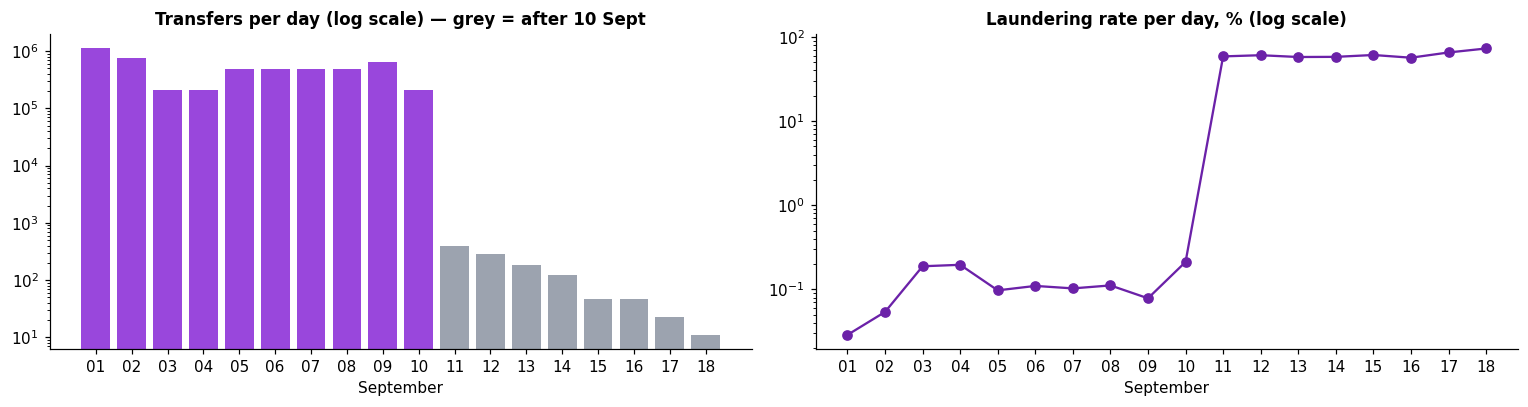

From 11 September onward:


,rows,laundering,rate_pct,laundering_without_scheme,schemes_crossing_11_sept,schemes_entirely_after
0,1108,655,59.12,0,102,7


In [5]:
daily = (pd.DataFrame({"day": j["Timestamp"].dt.normalize(), "y": Y})
         .groupby("day")["y"].agg(rows="size", laundering="sum").reset_index())
daily["rate_pct"] = 100 * daily["laundering"] / daily["rows"]
daily["day"] = daily["day"].dt.date
display(fmt_int(daily, ["rows", "laundering"]).round({"rate_pct": 3}))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
lab = pd.to_datetime(daily["day"]).dt.strftime("%d")
ax[0].bar(lab, daily["rows"], color=np.where(pd.to_datetime(daily["day"]) >= "2022-09-11", GREY, PURPLE))
ax[0].set_yscale("log"); ax[0].set_title("Transfers per day (log scale) — grey = after 10 Sept"); ax[0].set_xlabel("September")
ax[1].plot(lab, daily["rate_pct"], marker="o", color=DARK)
ax[1].set_yscale("log"); ax[1].set_title("Laundering rate per day, % (log scale)"); ax[1].set_xlabel("September")
plt.tight_layout(); plt.show()

after = ~BEFORE
tail = pd.DataFrame([{"rows": int(after.sum()), "laundering": int(Y[after].sum()),
                      "rate_pct": 100 * Y[after].mean(),
                      "laundering_without_scheme": int(((Y == 1) & ~HAS_ATT & after).sum())}])
span = j.loc[HAS_ATT, ["Attempt ID", "Timestamp"]].groupby("Attempt ID")["Timestamp"].agg(["min", "max"])
sch_tail = pd.DataFrame([{"schemes_crossing_11_sept": int(((span["min"] < CUT) & (span["max"] >= CUT)).sum()),
                          "schemes_entirely_after": int((span["min"] >= CUT).sum())}])
print("From 11 September onward:")
display(pd.concat([tail, sch_tail], axis=1).round(2))

From 11 Sept on there are only a few rows, almost all of them laundering steps of schemes that started
earlier. These are leftovers of the generator, not normal traffic, and would make the last days look like
a laundering flood.

**→ Rule.** Use **1–10 Sept only**. Rows from 11 Sept on are dropped (by the sampler and by 03). Schemes cut
by this are flagged `scheme_truncated`.

## A4. The label and the schemes

**Question.** Is every laundering row part of a known scheme? How big and how long are schemes?

In [6]:
box = np.select([(Y == 1) & HAS_ATT, Y == 1, HAS_ATT],
                ["1. Laundering, has a scheme (explained)", "2. Laundering, no scheme (unexplained)",
                 "3. Scheme but not laundering (must be 0)"], "4. Normal")
recon = pd.Series(box).value_counts().sort_index().rename_axis("box").reset_index(name="rows")
recon["share_of_laundering_pct"] = np.where(recon["box"].str[:1].isin(["1", "2"]),
                                            100 * recon["rows"] / Y.sum(), np.nan)
display(fmt_int(recon, ["rows"]).round(1))

L = Y == 1
lj = pd.DataFrame({"kind": np.where(HAS_ATT[L], "Explained", "Unexplained"),
                   "ach": (j["Payment Format"].to_numpy()[L] == "ACH"), "amount": PAID[L],
                   "cross_border": CB[L], "cross_bank": j["cross_bank"].to_numpy()[L],
                   "after": ~BEFORE[L]})
cmp = lj.groupby("kind").agg(rows=("kind", "size"), ach_pct=("ach", "mean"), median_amount=("amount", "median"),
                             cross_border_pct=("cross_border", "mean"), cross_bank_pct=("cross_bank", "mean"),
                             after_10_sept_pct=("after", "mean")).reset_index()
for c in ["ach_pct", "cross_border_pct", "cross_bank_pct", "after_10_sept_pct"]:
    cmp[c] *= 100
display(cmp.round(2))

fmt_split = (pd.DataFrame({"Payment Format": j["Payment Format"][L], "explained": HAS_ATT[L].astype(int),
                           "unexplained": (~HAS_ATT[L]).astype(int)})
             .groupby("Payment Format", observed=True)[["explained", "unexplained"]].sum().reset_index()
             .sort_values(["explained", "unexplained"], ascending=False).reset_index(drop=True))
print("Laundering rows by payment format:")
display(fmt_split)

,box,rows,share_of_laundering_pct
0,"1. Laundering, has a scheme (explained)","3,209",62.0
1,"2. Laundering, no scheme (unexplained)","1,968",38.0
2,4. Normal,"5,073,159",NaN


,kind,rows,ach_pct,median_amount,cross_border_pct,cross_bank_pct,after_10_sept_pct
0,Explained,3209,99.97,12576.93,74.29,97.51,20.41
1,Unexplained,1968,64.79,2955.04,37.60,98.63,0.00


Laundering rows by payment format:


,Payment Format,explained,unexplained
0,ACH,3208,1275
1,Bitcoin,1,55
2,Cheque,0,324
3,Credit Card,0,206
4,Cash,0,108


In [7]:
sch = pd.DataFrame({"Attempt ID": ATT[HAS_ATT].astype(np.int64),
                    "pattern": j["Pattern Type"].astype(str).to_numpy()[HAS_ATT],
                    "Timestamp": j["Timestamp"].to_numpy()[HAS_ATT], "af": AF[HAS_ATT], "at": AT[HAS_ATT],
                    "amount": PAID[HAS_ATT], "bank_from": j["Bank Name_from"].astype(str).to_numpy()[HAS_ATT],
                    "bank_to": j["Bank Name_to"].astype(str).to_numpy()[HAS_ATT],
                    "cross_border": CB[HAS_ATT], "cross_bank": j["cross_bank"].to_numpy()[HAS_ATT]})
g = sch.groupby("Attempt ID")
acc_long = pd.concat([sch[["Attempt ID", "af"]].set_axis(["Attempt ID", "acct"], axis=1),
                      sch[["Attempt ID", "at"]].set_axis(["Attempt ID", "acct"], axis=1)])
prof = pd.DataFrame({"pattern": g["pattern"].first(), "transfers": g.size(),
                     "span_days": (g["Timestamp"].max() - g["Timestamp"].min()).dt.total_seconds() / 86400,
                     "accounts": acc_long.groupby("Attempt ID")["acct"].nunique()}).reset_index()

by_type = prof.groupby("pattern").agg(
    schemes=("transfers", "size"), transfers=("transfers", "sum"),
    median_transfers=("transfers", "median"), max_transfers=("transfers", "max"),
    median_span_days=("span_days", "median"), median_accounts=("accounts", "median"),
).sort_values("schemes", ascending=False)
display(by_type.round(2))
print(f"All schemes: {len(prof)} | median transfers {prof['transfers'].median()} | max {prof['transfers'].max()} | "
      f"single-transfer schemes {(prof['transfers'] == 1).sum()} | median span {prof['span_days'].median():.2f} days | "
      f"max span {prof['span_days'].max():.2f} days")

shared = acc_long.drop_duplicates().groupby("acct").size().rename("schemes").reset_index()
print(f"\nAccounts in any scheme: {len(shared):,} | in more than one scheme: {(shared['schemes'] > 1).sum():,} "
      f"| most schemes for one account: {shared['schemes'].max()}")

,schemes,transfers,median_transfers,max_transfers,median_span_days,median_accounts
pattern,,,,,,
CYCLE,54,287,4.0,12,3.00,4.0
GATHER-SCATTER,51,716,14.0,28,6.28,15.0
BIPARTITE,49,263,4.0,15,1.01,8.0
FAN-OUT,48,342,7.0,16,3.19,8.0
SCATTER-GATHER,44,626,14.0,32,3.70,9.0
STACK,43,466,10.0,30,3.05,15.0
RANDOM,41,191,3.0,11,1.92,4.0
FAN-IN,40,318,8.0,16,3.54,9.0


All schemes: 370 | median transfers 6.5 | max 32 | single-transfer schemes 43 | median span 3.11 days | max span 8.43 days

Accounts in any scheme: 3,170 | in more than one scheme: 100 | most schemes for one account: 32


Some laundering rows have no scheme ("unexplained"). Schemes are small groups of transfers that can span
several days and share accounts.

**→ Rule.** The label is `Is Laundering` (all laundering rows, explained or not). `Attempt ID` /
`Pattern Type` are for evaluation only (catch rate per scheme type). Because schemes span days, a split by
date must keep **each scheme whole** (B4).

## A5. Self-transfers

**Question.** The join flags `self_transfer` when the **account number** is the same on both sides. But the
same number can exist at two different banks. What is the right definition, and do self-transfers matter?

In [8]:
same_num = j["self_transfer"].to_numpy() == 1
same_bank_and_num = same_num & (j["From Bank"].to_numpy() == j["To Bank"].to_numpy())
st = pd.DataFrame([
    ("Same account number (join flag)", int(same_num.sum()), int(Y[same_num].sum())),
    ("Same bank AND same account number", int(same_bank_and_num.sum()), int(Y[same_bank_and_num].sum())),
    ("Same number, different bank", int((same_num & ~same_bank_and_num).sum()), int(Y[same_num & ~same_bank_and_num].sum())),
], columns=["definition", "rows", "laundering"])
display(fmt_int(st, ["rows", "laundering"]))
print(f"Different-currency rows that are self-transfers: {100 * same_bank_and_num[CHG].mean():.2f}%")
sf = risk_by("Payment Format", mask=same_bank_and_num)
display(fmt_int(sf[["value", "rows", "laundering"]], ["rows", "laundering"]))

,definition,rows,laundering
0,Same account number (join flag),"591,212",11
1,Same bank AND same account number,"591,212",11
2,"Same number, different bank",0,0


Different-currency rows that are self-transfers: 96.97%


,value,rows,laundering
0,ACH,"71,347",11
1,Bitcoin,"26,317",0
2,Cash,"1,455",0
3,Cheque,"6,066",0
4,Credit Card,"4,176",0
5,Reinvestment,"481,056",0
6,Wire,795,0


A self-transfer moves money inside one account, almost always between currencies (Reinvestment and
conversions). Almost none are labelled laundering: the table above shows how many are (a handful of ACH
rows on the real file). The generator often puts one in the same minute **before** a laundering transfer
(the conversion step, B15).

**→ Rule.** Self-transfer = **same bank AND same account**. Self-transfers are not scored and never
counted as account activity; they are only used for the `conversion_before` flag. **Known limitation:**
the few laundering self-transfers in 1–10 Sept are never scored (03 reports how many: "scored + self").

## A6. Bank names vs bank IDs

**Question.** Is one bank ID one bank?

In [9]:
cb = risk_by(np.where(j["cross_bank"].to_numpy() == 1, "Different bank", "Same bank"))
display(fmt_int(cb, ["rows", "laundering"]).round(4))
name_id = pd.concat([pd.DataFrame({"name": j["Bank Name_from"], "id": j["From Bank"]}),
                     pd.DataFrame({"name": j["Bank Name_to"], "id": j["To Bank"]})]).drop_duplicates()
ids = name_id.groupby("name", observed=True)["id"].nunique()
del name_id
print(f"Bank names: {len(ids):,} | names with more than one bank ID: {(ids > 1).sum():,} | most IDs for one name: {ids.max()}")

,value,rows,laundering,rate_pct,share_of_laundering_pct,share_of_rows_pct
0,Different bank,"4,383,014","5,070",0.1157,97.9332,86.3081
1,Same bank,"695,322",107,0.0154,2.0668,13.6919


Bank names: 20,053 | names with more than one bank ID: 468 | most IDs for one name: 48


**→ Rule.** "Different bank" is decided by bank **name** (`cross_bank`). An account is identified by
`bank ID : account number` (an account number alone repeats across banks).

## A7. Exchange rates

**Question.** Is there one fixed exchange rate per currency, so amounts can be compared in one unit?

In [10]:
m = ((j["Receiving Currency"] == "US Dollar") & (j["Payment Currency"] != "US Dollar")).to_numpy() & (RECV > 0.01)
r = pd.DataFrame({"currency": j["Payment Currency"].astype(str).to_numpy()[m], "ratio": PAID[m] / RECV[m]})
gr = r.groupby("currency")["ratio"]
fxt = pd.DataFrame({"units_per_usd": gr.median(), "rows_used": gr.size(),
                    "relative_spread": gr.std() / gr.mean()}).reset_index()
fxt = (pd.concat([fxt, pd.DataFrame([{"currency": "US Dollar", "units_per_usd": 1.0, "rows_used": np.nan,
                                      "relative_spread": 0.0}])])
       .sort_values("currency").reset_index(drop=True))
display(fxt.round(6))
print(f"Largest relative spread of a rate: {fxt['relative_spread'].max() * 100:.2f}%  -> one fixed rate per currency")
FX = dict(zip(fxt["currency"], fxt["units_per_usd"]))
# currencies never paid straight into USD: chain through any other pair (median rate per pair)
pc_, rc_ = j["Payment Currency"].astype(str).to_numpy(), j["Receiving Currency"].astype(str).to_numpy()
def pair_rates(min_amount):
    mp = (pc_ != rc_) & (PAID > 0) & (RECV > 0) & (PAID >= min_amount) & (RECV >= min_amount)
    return pd.DataFrame({"pay": pc_[mp], "rcv": rc_[mp], "r": RECV[mp] / PAID[mp]}).groupby(["pay", "rcv"])["r"].median()


pr_ = pair_rates(1.0)
small_ = pair_rates(0.0)                      # tiny amounts (Bitcoin) only where no pair of 1+ exists
pr_ = pd.concat([pr_, small_[~small_.index.isin(pr_.index)]])
for _ in range(len(pr_)):
    for (pay, rcv), r in pr_.items():
        if pay in FX and rcv not in FX:
            FX[rcv] = FX[pay] * r
        elif rcv in FX and pay not in FX:
            FX[pay] = FX[rcv] / r
chained = sorted(set(FX) - set(fxt["currency"]))
if chained:
    print("Rates found through another currency:", {c: round(FX[c], 6) for c in chained})
missing_fx = len(set(j["Payment Currency"].cat.categories[np.unique(j["Payment Currency"].cat.codes)]) - set(FX))
print(f"Currencies without a rate: {missing_fx}")

rate_by_code = np.array([FX.get(c, np.nan) for c in j["Payment Currency"].cat.categories])
USD = PAID / rate_by_code[j["Payment Currency"].cat.codes.to_numpy()]   # amount in US Dollars (NaN = no rate)
HAS_USD = ~np.isnan(USD)
usd = (pd.DataFrame({"laundering": Y[HAS_USD], "u": USD[HAS_USD]}).groupby("laundering")["u"]
       .quantile([0.25, 0.5, 0.75, 0.99]).unstack()
       .set_axis(["p25_usd", "median_usd", "p75_usd", "p99_usd"], axis=1).reset_index())
print("\nAmounts converted to US Dollars:")
display(usd.round(2))

,currency,units_per_usd,rows_used,relative_spread
0,Australian Dollar,1.412800,146.0,0.000235
1,Bitcoin,0.000084,13.0,0.000624
2,Brazil Real,5.646500,80.0,0.000061
3,Canadian Dollar,1.319300,559.0,0.010567
4,Euro,0.853400,11060.0,0.000930
5,Mexican Peso,21.143100,291.0,0.001826
6,Ruble,77.804353,169.0,0.000640
7,Rupee,73.443994,803.0,0.002997
8,Saudi Riyal,3.751100,64.0,0.000082
9,Shekel,3.377002,45.0,0.005615


Largest relative spread of a rate: 1.06%  -> one fixed rate per currency
Currencies without a rate: 0

Amounts converted to US Dollars:


,laundering,p25_usd,median_usd,p75_usd,p99_usd
0,0,158.00,891.06,5273.87,3099715.32
1,1,2160.56,5878.81,13758.50,15793198.13


The rate spread is tiny: the generator uses one fixed rate per currency. A currency that is never paid
straight into USD gets its rate through another currency.

**→ Rule.** Convert every amount to USD with one rate per currency. `03` learns this table from the
**train split** (not the full file), so nothing from val/test leaks in.

## A8. Hub accounts

**Question.** A few accounts trade with a huge number of others. How many, and how much of the traffic do
they carry?

In [11]:
CPTY = distinct_counterparties(AF, AT, N_ACCT)
DEG = np.bincount(AF, minlength=N_ACCT) + np.bincount(AT, minlength=N_ACCT)
LAU = (np.bincount(AF, weights=Y, minlength=N_ACCT) + np.bincount(AT, weights=Y, minlength=N_ACCT)).astype(int)
hub = np.flatnonzero(CPTY >= 500)
print(f"Accounts: {N_ACCT:,} | hubs (500+ distinct counterparties): {len(hub)} | "
      f"share of all row-sides touching a hub: {100 * DEG[hub].sum() / (2 * len(j)):.1f}% | "
      f"hubs touching laundering: {(LAU[hub] > 0).sum()}")
ht_ = pd.DataFrame({"acct": ACCT[hub].astype(str), "transfers": DEG[hub], "counterparties": CPTY[hub],
                    "laundering_rows": LAU[hub]}).sort_values("transfers", ascending=False).head(10)
display(fmt_int(ht_, ["transfers", "counterparties", "laundering_rows"]))
q_ = np.quantile(CPTY[DEG > 0], [0.5, 0.9, 0.99, 0.999])
print("Distinct counterparties per account - median / p90 / p99 / p99.9:", q_.round(1))

Accounts: 515,088 | hubs (500+ distinct counterparties): 15 | share of all row-sides touching a hub: 4.5% | hubs touching laundering: 15


,acct,transfers,counterparties,laundering_rows
0,70:100428660,"169,756","14,775",243
1,70:1004286A8,"103,671","9,174",158
11,70:100428978,"20,647","1,851",29
2,70:1004286F0,"18,771","1,630",21
4,70:100428780,"17,381","1,482",21
12,70:1004289C0,"16,926","1,500",13
6,70:100428810,"16,540","1,452",26
5,70:1004287C8,"14,277","1,236",16
3,70:100428738,"13,854","1,187",23
14,70:100428A51,"13,101","1,161",18


Distinct counterparties per account - median / p90 / p99 / p99.9: [ 2.  6. 13. 32.]


Hubs are far outside the normal range and carry a large share of all traffic. If the sampler picked a hub
as a seed, its full history would flood the subsample.

**→ Rule.** Hub = **500+ distinct counterparties**. Hubs are never sampling seeds (02). The model gets
`snd_hub` / `rcv_hub` flags, with the hub list learned on train dates only (B16).

## A9. What the full file is still used for

Part B works on the subsample, but the full file stays in use:
1. **Account history for every feature** (B6): counts for a subsample row look at the account's
   earlier transfers in the full file.
2. **Rules 1–6** above: cutoff, self-transfers, scheme handling, bank names, FX method, hub threshold.
3. **The investigation agents** (later step) look up an account's history in it, up to the alert time only.

---
# Part B — The subsample: what the model is trained on

Everything from here uses the **time-split subsample** (`data/processed/sample/time/`, built by
`src/02_subsample_split.py time`). Those are exactly the rows `03_PREPROCESSING` turns into features and
`04_MODELLING` trains and tests on.

Order of work:
1. **B1–B5: can the subsample be trusted, and how must it be handled?** Integrity, weights, leakage
   columns, the split, rows that cannot be scored fairly.
2. **B6: where account history must come from.**
3. **B7–B17: the signals, on the TRAIN split only, weighted.** Every rate is a weighted estimate of the
   real population rate, not the inflated rate inside the sample. Val and test are not looked at, so no
   feature choice is made by peeking at the test days.
4. **B18: is each signal stable from day to day** (train and val days only).
5. **B19: the rules handed to preprocessing.**

Each section ends with **→ Rule**: the decision `03_PREPROCESSING` implements.

## B1. Load the subsample and check it against the full file

**Question.** Are the subsample rows real rows of the full file? Does it keep every laundering row of
1–10 Sept? Do the seed accounts carry their complete history, and are schemes kept whole inside one split?

In [12]:
TIME_DIR = ROOT / "data" / "processed" / "sample" / "time"
NEEDED = [TIME_DIR / f for f in ["train.parquet", "val.parquet", "test.parquet", "accounts.parquet"]]
if RUN_PIPELINE or not all(p.exists() for p in NEEDED):
    print("time-split subsample missing -> running src/02_subsample_split.py time (~1 min)")
    run_script("02_subsample_split.py", "time")
if not all(p.exists() for p in NEEDED):
    raise FileNotFoundError(f"subsample not found in {TIME_DIR} - run `python src/02_subsample_split.py time`")

SPLITS = ["train", "val", "test"]
s = pd.concat([pd.read_parquet(TIME_DIR / f"{n}.parquet").assign(split=n) for n in SPLITS], ignore_index=True)
sacc = pd.read_parquet(TIME_DIR / "accounts.parquet")


def to_codes(series, cats):
    """Text -> the full file's category codes (-1 = not in the full file)."""
    return pd.Categorical(series.astype(str), categories=cats).codes.astype(np.int64)


SAF, SAT = to_codes(s["acct_from"], ACCT), to_codes(s["acct_to"], ACCT)     # accounts as full-file codes
SY = s["Is Laundering"].to_numpy().astype(np.int64)
SW = s["weight"].to_numpy(float)
ST = ((s["Timestamp"] - T0) // pd.Timedelta(seconds=1)).to_numpy(np.int64)
SSPLIT = s["split"].to_numpy()
SATT = s["Attempt ID"].to_numpy(dtype="float64", na_value=np.nan)
SHAS = ~np.isnan(SATT)
REACH = (s["seed_from"].to_numpy() == 1) | (s["seed_to"].to_numpy() == 1)


def own_split(ts):
    return np.select([ts < pd.Timestamp("2022-09-07"), ts < pd.Timestamp("2022-09-08")], ["train", "val"], "test")


SOWN = own_split(s["Timestamp"].to_numpy())

# 1) every subsample row is a row of the full file (row key compared as a multiset of hashes)
KEY = ["Timestamp", "From Bank", "Account", "To Bank", "Account.1", "Amount Paid", "Amount Received",
       "Payment Format", "Payment Currency", "Receiving Currency"]


def key_hashes(cols):
    """One 64-bit hash per row of the 10-column key, as sorted unique hashes + counts."""
    return np.unique(pd.util.hash_pandas_object(pd.DataFrame(cols), index=False).to_numpy(), return_counts=True)


cat_key = lambda c: isinstance(j[c].dtype, pd.CategoricalDtype)
hs_, cs_ = key_hashes({c: to_codes(s[c], j[c].cat.categories) if cat_key(c) else s[c].to_numpy() for c in KEY})
hf_, cf_ = key_hashes({c: (j[c].cat.codes.to_numpy() if cat_key(c) else j[c].to_numpy())[BEFORE] for c in KEY})
p_ = np.minimum(np.searchsorted(hf_, hs_), len(hf_) - 1)
not_found = int(np.clip(cs_ - np.where(hf_[p_] == hs_, cf_[p_], 0), 0, None).sum())
del hs_, cs_, hf_, cf_

# 2) seed accounts: same number of transfers in the subsample as in the full file
full_n = np.bincount(AF[BEFORE], minlength=N_ACCT) + np.bincount(AT[BEFORE & (AF != AT)], minlength=N_ACCT)
samp_n = np.bincount(SAF, minlength=N_ACCT) + np.bincount(SAT[SAF != SAT], minlength=N_ACCT)
seeds = to_codes(sacc.loc[sacc["full_history"].astype(bool), "acct"], ACCT)

# 3) schemes: complete and inside one split
fa_cnt = pd.Series(ATT[BEFORE & HAS_ATT]).value_counts()
sa_cnt = pd.Series(SATT[SHAS]).value_counts()
ix = fa_cnt.index.union(sa_cnt.index)

checks = [
    ("Subsample rows not found in the full file", not_found, 0),
    ("Account codes not found in the full file", int((SAF < 0).sum() + (SAT < 0).sum()), 0),
    ("Laundering rows of 1-10 Sept missing from the subsample", int(Y[BEFORE].sum()) - int(SY.sum()), 0),
    ("Schemes whose row count differs from the full file", int((fa_cnt.reindex(ix) != sa_cnt.reindex(ix)).sum()), 0),
    ("Schemes spread over more than one split",
     int((pd.Series(SSPLIT[SHAS]).groupby(SATT[SHAS]).nunique() > 1).sum()), 0),
    ("Seed accounts with an incomplete history", int((full_n[seeds] != samp_n[seeds]).sum()), 0),
    ("Rows dated 11 Sept or later", int((s["Timestamp"] >= CUT).sum()), 0),
    ("Rows with weight below 1", int((SW < 1).sum()), 0),
    ("Laundering rows with weight other than 1", int(((SY == 1) & (SW != 1)).sum()), 0),
]
tab = pd.DataFrame(checks, columns=["Check", "Got", "Expected"])
tab["OK"] = np.where(tab["Got"] == tab["Expected"], "PASS", "FAIL")
display(tab)
print(f"{(tab['OK'] == 'PASS').sum()} / {len(tab)} checks passed")

n_full = int(BEFORE.sum())
print(f"\nSubsample: {len(s):,} rows = {100 * len(s) / n_full:.1f}% of the {n_full:,} full rows of 1-10 Sept | "
      f"laundering {int(SY.sum()):,} | accounts {len(sacc):,} "
      f"(full history: {int(sacc['full_history'].astype(bool).sum()):,})")
print(f"Sum of weights: {SW.sum():,.0f} vs {n_full:,} real rows ({100 * (SW.sum() / n_full - 1):+.2f}%)")

time-split subsample missing -> running src/02_subsample_split.py time (~1 min)
[   0.2s] reading joined file, dropping 11-18 Sept residue...
   joined file: 5,078,336 rows, 5,177 positives
   after residue drop: 5,077,228 rows, 4,522 positives (1,108 rows and 655 positives dropped)
[  17.6s] profiling accounts...
   accounts: 515,078
   hubs (>= 500 counterparties): 15, 452,751 row-appearances  (EDA: 55 hubs at Oasis Thrift)
   laundering accounts kept as seeds: 5,847 (+ 15 hubs touching laundering, not seeded)
[  57.2s] finding Q for ~750,000 rows...
[  60.4s] Q = 0.06862 gives 750,045 rows
[  60.4s] size table for different Q...

         Q        rows  positives   rate %  enrichment  % of data
    0.0000     165,687      4,522    2.729       30.6x       3.3%  <- floor (not usable)
    0.0100     252,580      4,522    1.790       20.1x       5.0%
    0.0200     340,653      4,522    1.327       14.9x       6.7%
    0.0300     425,906      4,522    1.062       11.9x       8.4%
    0.

,Check,Got,Expected,OK
0,Subsample rows not found in the full file,0,0,PASS
1,Account codes not found in the full file,0,0,PASS
2,Laundering rows of 1-10 Sept missing from the ...,0,0,PASS
3,Schemes whose row count differs from the full ...,0,0,PASS
4,Schemes spread over more than one split,0,0,PASS
5,Seed accounts with an incomplete history,0,0,PASS
6,Rows dated 11 Sept or later,0,0,PASS
7,Rows with weight below 1,0,0,PASS
8,Laundering rows with weight other than 1,0,0,PASS


9 / 9 checks passed

Subsample: 750,045 rows = 14.8% of the 5,077,228 full rows of 1-10 Sept | laundering 4,522 | accounts 118,560 (full history: 40,561)
Sum of weights: 5,064,397 vs 5,077,228 real rows (-0.25%)


**→ Rule.** All checks must pass before preprocessing. `03_PREPROCESSING` re-matches every subsample row
to the full file on the same 10-column key and stops if any row fails to match exactly once.

## B2. Why every number needs the weights

**Question.** The sampler keeps every laundering account but only a fraction of the normal ones. How wrong
are rates and shares if the subsample is used as it is, and does `weight` (= 1 / chance of being picked)
fix them?

In [13]:
def measure(kind, cond, y, w):
    if kind == "rate":
        return 100 * np.sum(w * y * cond) / np.sum(w * cond)
    return 100 * np.sum(w * cond) / np.sum(w)


fmt_full, fmt_s = j["Payment Format"].astype(str).to_numpy(), s["Payment Format"].astype(str).to_numpy()
cb_full, cb_s = CB, s["cross_border"].to_numpy()
ck_full, ck_s = j["cross_bank"].to_numpy(), s["cross_bank"].to_numpy()
rows = []
for kind, name, cf, cs in [
    ("rate", "Laundering rate %, overall", np.ones(len(j), bool), np.ones(len(s), bool)),
    ("rate", "Laundering rate %, cross-border", cb_full == 1, cb_s == 1),
    ("rate", "Laundering rate %, same country", cb_full == 0, cb_s == 0),
    ("rate", "Laundering rate %, different bank", ck_full == 1, ck_s == 1),
    ("rate", "Laundering rate %, ACH", fmt_full == "ACH", fmt_s == "ACH"),
    ("share", "Share % of rows: ACH", fmt_full == "ACH", fmt_s == "ACH"),
    ("share", "Share % of rows: Cheque", fmt_full == "Cheque", fmt_s == "Cheque"),
    ("share", "Share % of rows: cross-border", cb_full == 1, cb_s == 1),
]:
    rows.append((name, measure(kind, cf, Y, BEFORE.astype(float)), measure(kind, cs, SY, SW),
                 measure(kind, cs, SY, np.ones(len(s)))))
rep = pd.DataFrame(rows, columns=["Measure", "Full file (truth)", "Subsample weighted", "Subsample raw"])
rep["Weighted error %"] = 100 * (rep["Subsample weighted"] / rep["Full file (truth)"] - 1)
rep["Raw error %"] = 100 * (rep["Subsample raw"] / rep["Full file (truth)"] - 1)
display(rep.round(4))

ess = SW.sum() ** 2 / (SW ** 2).sum()
print(f"Raw laundering rate is {rep.loc[0, 'Subsample raw'] / rep.loc[0, 'Full file (truth)']:.1f}x the real one.")
print(f"Effective sample size of the weighted subsample: {ess:,.0f} of {len(s):,} rows "
      f"({100 * ess / len(s):.1f}%) - weighted estimates are noisier than the row count suggests.")

,Measure,Full file (truth),Subsample weighted,Subsample raw,Weighted error %,Raw error %
0,"Laundering rate %, overall",0.0891,0.0893,0.6029,0.2534,576.9231
1,"Laundering rate %, cross-border",0.1867,0.1879,1.2063,0.6283,546.0048
2,"Laundering rate %, same country",0.0510,0.0510,0.3516,0.1079,589.7974
3,"Laundering rate %, different bank",0.1012,0.1017,0.6511,0.4652,543.3528
4,"Laundering rate %, ACH",0.6383,0.6452,3.8401,1.0771,501.5860
5,Share % of rows: ACH,11.8113,11.7150,13.2904,-0.8150,12.5231
6,Share % of rows: Cheque,36.7195,36.6231,38.1040,-0.2625,3.7705
7,Share % of rows: cross-border,28.0556,27.9511,29.3984,-0.3726,4.7861


Raw laundering rate is 6.8x the real one.
Effective sample size of the weighted subsample: 579,463 of 750,045 rows (77.3%) - weighted estimates are noisier than the row count suggests.


**→ Rule.** `weight` goes everywhere a number is learned or reported: caps, category levels, the lift
tables in this EDA, and every model metric. The model may train with or without weights (04 picks the
choice on val), but nothing is ever **measured** without them.

## B3. Columns that give the answer away

**Question.** The sampler adds bookkeeping columns, and `accounts.parquet` describes each account using the
labels. Which of them predict laundering only because of how the subsample was built?

In [14]:
def raw_rate(values, name):
    d = pd.DataFrame({"value": values, "y": SY}).groupby("value")["y"].agg(rows="size", laundering="sum").reset_index()
    d.insert(0, "column", name)
    d["raw_rate_pct"] = 100 * d["laundering"] / d["rows"]
    return d


touch = pd.Series(sacc["touches_laundering"].astype(int).to_numpy(), index=sacc["acct"].astype(str))
leak = pd.concat([
    raw_rate(np.where(SW == 1, "weight = 1", "weight > 1"), "weight / incl_prob"),
    raw_rate(s["seed_from"].to_numpy() + s["seed_to"].to_numpy(), "seed_from + seed_to"),
    raw_rate(s["scheme_truncated"].astype(int).to_numpy(), "scheme_truncated"),
    raw_rate(s["scheme_moved"].astype(int).to_numpy(), "scheme_moved"),
    raw_rate(np.where(SHAS, "filled", "empty"), "Attempt ID / Pattern Type"),
    raw_rate(touch.reindex(s["acct_from"].astype(str)).to_numpy(), "touches_laundering (sender)"),
], ignore_index=True)
display(fmt_int(leak, ["rows", "laundering"]).round(3))

,column,value,rows,laundering,raw_rate_pct
0,weight / incl_prob,weight = 1,"165,687","4,522",2.729
1,weight / incl_prob,weight > 1,"584,358",0,0.000
2,seed_from + seed_to,1,"665,187",633,0.095
3,seed_from + seed_to,2,"84,858","3,889",4.583
4,scheme_truncated,0,"749,408","3,885",0.518
5,scheme_truncated,1,637,637,100.000
6,scheme_moved,0,"748,685","3,162",0.422
7,scheme_moved,1,"1,360","1,360",100.000
8,Attempt ID / Pattern Type,empty,"747,491","1,968",0.263
9,Attempt ID / Pattern Type,filled,"2,554","2,554",100.000


Any value of these columns with a raw rate of 100% or 0% is the sampling design (or the label itself)
showing through, not behaviour a bank could observe.

**→ Rule.** Never a feature: `Attempt ID`, `Pattern Type`, `weight`, `incl_prob`, `seed_from`, `seed_to`,
`scheme_truncated`, `scheme_moved`, the split columns, and everything in `accounts.parquet`
(`touches_laundering`, `appearances`, `n_cpty`, `is_hub`, `full_history`). Also out: account, entity and
bank IDs and names (they identify, they do not describe). `03` writes the list to `artifacts.json →
leak_columns`, and 03 and 04 both check it.

## B4. The split: train 1–6 Sept, val 7 Sept, test 8–10 Sept

**Question.** How big is each split, how different is its laundering rate, and how many scheme rows had
to move because their scheme ended in a later split? How many test launderers were already seen in train?

In [15]:
d = pd.DataFrame({"split": SSPLIT, "y": SY, "w": SW, "wy": SW * SY, "att": SATT,
                  "moved": s["scheme_moved"].to_numpy(), "trunc": s["scheme_truncated"].to_numpy(), "reach": REACH})
sp = d.groupby("split").agg(rows=("y", "size"), laundering=("y", "sum"), w=("w", "sum"), wy=("wy", "sum"),
                            schemes=("att", "nunique"), rows_moved_in=("moved", "sum"),
                            unreachable_rows=("reach", lambda r: int((~r).sum()))).reindex(SPLITS)
sp.insert(2, "weighted_rate_pct", 100 * sp["wy"] / sp["w"])
sp["truncated_schemes"] = [d.loc[(d["split"] == n) & d["trunc"], "att"].nunique() for n in SPLITS]
display(fmt_int(sp.drop(columns=["w", "wy"]).reset_index(), ["rows", "laundering"]).round(4))
print(f"Test weighted rate / train weighted rate: {sp.loc['test', 'weighted_rate_pct'] / sp.loc['train', 'weighted_rate_pct']:.2f}x")

a = pd.DataFrame({"acct": np.concatenate([SAF, SAT]), "sp": np.concatenate([SSPLIT, SSPLIT]),
                  "y": np.concatenate([SY, SY])})
per = pd.DataFrame({"in_train": (a["sp"] == "train").groupby(a["acct"]).any(),
                    "launders_train": ((a["sp"] == "train") & (a["y"] == 1)).groupby(a["acct"]).any(),
                    "launders_test": ((a["sp"] == "test") & (a["y"] == 1)).groupby(a["acct"]).any()})
del a
n_lt = int(per["launders_test"].sum())
print(f"Accounts laundering in test: {n_lt:,} | also active in train: "
      f"{100 * (per['launders_test'] & per['in_train']).sum() / max(n_lt, 1):.1f}% | also laundering in train: "
      f"{100 * (per['launders_test'] & per['launders_train']).sum() / max(n_lt, 1):.1f}%")

,split,rows,laundering,weighted_rate_pct,schemes,rows_moved_in,unreachable_rows,truncated_schemes
0,train,"465,933","1,995",0.0616,124,0,0,0
1,val,"74,996",323,0.0669,31,142,0,1
2,test,"209,116","2,204",0.1643,208,1218,0,101


Test weighted rate / train weighted rate: 2.67x
Accounts laundering in test: 2,725 | also active in train: 97.8% | also laundering in train: 3.7%


**→ Rule.**
- **Fitting uses train only.** Val chooses settings (weighting, model shape). Test is opened once, at the end.
- **Schemes stay whole** inside one split, so a model never sees half a scheme in train and the other half
  in test. Rows moved forward are flagged `scheme_moved`.
- **Test metrics use each row's own date** (`own_date_split`), so moved rows do not inflate them.
- The rate differs by split (more of the test-period schemes are cut short at 10 Sept), so compare models
  on PR-AUC against each split's own prevalence, not on raw precision.
- Many test launderers also appear in train. A **group split** (whole accounts kept apart) is kept as a
  robustness check.

## B5. Rows that cannot be scored fairly

**Question.** A row's accounts are in the subsample either because they are **seeds** (picked, full
history) or only because a seed traded with them. What happens to rows where **neither** side is a seed?

In [16]:
g = pd.DataFrame({"seed_from": s["seed_from"].to_numpy(), "seed_to": s["seed_to"].to_numpy(), "y": SY, "w": SW})
seed_tab = g.groupby(["seed_from", "seed_to"]).agg(rows=("y", "size"), laundering=("y", "sum")).reset_index()
seed_tab["raw_rate_pct"] = 100 * seed_tab["laundering"] / seed_tab["rows"]
display(fmt_int(seed_tab, ["rows", "laundering"]).round(2))
print(f"Unreachable rows (no seed on either side): {int((~REACH).sum()):,}, "
      f"of which laundering: {100 * SY[~REACH].mean() if (~REACH).any() else 0:.1f}%")

,seed_from,seed_to,rows,laundering,raw_rate_pct
0,0,1,"349,261",633,0.18
1,1,0,"315,926",0,0.00
2,1,1,"84,858","3,889",4.58


Unreachable rows (no seed on either side): 0, of which laundering: 0.0%


A row with no seed side can only be in the subsample because it is a laundering row the sampler had to
keep (for example a laundering account trading with a hub, which is never a seed). Its label is fixed by
construction, so it would teach the model and the metrics nothing real.

**→ Rule.** Rows with `seed_from = seed_to = 0` stay in the files but are **left out of fitting and of
every metric**. They are reported separately.

## B6. Account history: full file or subsample?

**Question.** Features like "how many transfers did the sender make in the last 48 h" need each account's
earlier transfers. If they are counted **inside the subsample**, accounts that are only seen as a
counterparty have most of their history missing. Is that error the same for laundering and normal rows?

The cell below builds the point-in-time features for every scored subsample row (self-transfers left out)
with the same definitions as `03_PREPROCESSING`, using the **full file** as history. It also builds three
counts with the subsample as history, for the comparison.

In [17]:
S2 = np.int64(2 ** 21)          # key = id * S2 + seconds (2^21 s = 24 days)
H48, H24, M60 = 48 * 3600, 24 * 3600, 3600


def keyed(ids, secs):
    return np.asarray(ids, np.int64) * S2 + np.asarray(secs, np.int64)


def count_in_window(ev_id, ev_t, q_id, lo, hi):
    """Events with the same id and lo <= time < hi."""
    k = np.sort(keyed(ev_id, ev_t))
    return (np.searchsorted(k, keyed(q_id, np.maximum(hi, 0)), "left")
            - np.searchsorted(k, keyed(q_id, np.maximum(lo, 0)), "left"))


def last_before(ev_id, ev_t, q_id, q_t):
    """Latest event time with the same id and time < q_t, or -1."""
    k = np.unique(keyed(ev_id, ev_t))
    q_id = np.asarray(q_id, np.int64)
    pos = np.searchsorted(k, keyed(q_id, q_t), "left") - 1
    cand = k[np.maximum(pos, 0)]
    return np.where((pos >= 0) & (cand // S2 == q_id), cand % S2, -1)


def distinct_in_window(owner, other, ev_t, q_owner, q_t, window):
    """Distinct `other` accounts seen with `owner` in [t - window, t). An earlier transfer of a pair is
    the pair's first one inside the window exactly when t is in (max(e, previous + window), e + window]."""
    pair = np.asarray(owner, np.int64) * (int(other.max()) + 1) + np.asarray(other, np.int64)
    o = np.lexsort((ev_t, pair))
    pr, t = pair[o], np.asarray(ev_t, np.int64)[o]
    prev = np.where(np.r_[False, pr[1:] == pr[:-1]], np.r_[0, t[:-1]], -10 * window)
    own = np.asarray(owner, np.int64)[o]
    ks, ke = np.sort(keyed(own, np.maximum(t, prev + window))), np.sort(keyed(own, t + window))
    q = keyed(q_owner, q_t)
    return np.searchsorted(ks, q, "left") - np.searchsorted(ke, q, "left")


# self-transfer = same bank AND same account (A5); history = full file, 1-10 Sept, no self-transfers
SELF2 = (j["From Bank"].to_numpy() == j["To Bank"].to_numpy()) & \
        (j["Account"].cat.codes.to_numpy() == j["Account.1"].cat.codes.to_numpy())
HB = np.flatnonzero(BEFORE & ~SELF2)
HSF = np.flatnonzero(BEFORE & SELF2)
ha, hb, ht = AF[HB], AT[HB], TS[HB]
s_self = (s["From Bank"].to_numpy() == s["To Bank"].to_numpy()) & \
         (s["Account"].astype(str).to_numpy() == s["Account.1"].astype(str).to_numpy())
q = np.flatnonzero(~s_self)                        # scored subsample rows
a, b, t = SAF[q], SAT[q], ST[q]

pid, pinv = np.unique(np.concatenate([ha * N_ACCT + hb, a * N_ACCT + b, b * N_ACCT + a]), return_inverse=True)
hp, qp, qr = pinv[:len(HB)], pinv[len(HB):len(HB) + len(q)], pinv[len(HB) + len(q):]

F = pd.DataFrame({"y": SY[q], "w": SW[q], "split": SSPLIT[q], "own_split": SOWN[q], "reach": REACH[q],
                  "day": s["Timestamp"].dt.normalize().to_numpy()[q], "explained": SHAS[q]})
F["hc"] = t >= TS.min() + H48                      # 48 h of history exist before this row
F["snd_sent_48h"] = count_in_window(ha, ht, a, t - H48, t)
F["snd_recv_48h"] = count_in_window(hb, ht, a, t - H48, t)
F["rcv_recv_48h"] = count_in_window(hb, ht, b, t - H48, t)
F["rcv_sent_48h"] = count_in_window(ha, ht, b, t - H48, t)
F["snd_cpty_48h"] = distinct_in_window(ha, hb, ht, a, t, H48)
F["rcv_cpty_48h"] = distinct_in_window(hb, ha, ht, b, t, H48)
F["pair_prev_48h"] = count_in_window(hp, ht, qp, t - H48, t)
F["snd_sent_24h"] = count_in_window(ha, ht, a, t - H24, t)
F["snd_sent_60m"] = count_in_window(ha, ht, a, t - M60, t)
F["rcv_recv_24h"] = count_in_window(hb, ht, b, t - H24, t)
F["rcv_recv_60m"] = count_in_window(hb, ht, b, t - M60, t)
F["new_pair_48h"] = (F["pair_prev_48h"] == 0).astype(int)
F["reverse_pair_48h"] = (count_in_window(hp, ht, qr, t - H48, t) > 0).astype(int)
F["snd_quiet_48h"] = ((F["snd_sent_48h"] == 0) & (F["snd_recv_48h"] == 0)).astype(int)
F["rcv_quiet_48h"] = ((F["rcv_recv_48h"] == 0) & (F["rcv_sent_48h"] == 0)).astype(int)

# money in -> money out (amounts in USD with the A7 rates)
pay_rate = np.array([FX.get(c, np.nan) for c in s["Payment Currency"].astype(str).to_numpy()[q]])
F["amount_usd"] = s["Amount Paid"].to_numpy()[q] / pay_rate
last = last_before(hb, ht, a, t)
F["snd_dwell_h"] = np.where(last >= 0, np.minimum((t - last) / 3600, 24.0), 24.0)
rrate = np.array([FX.get(c, np.nan) for c in j["Receiving Currency"].cat.categories])
usd_in = RECV[HB] / rrate[j["Receiving Currency"].cat.codes.to_numpy()[HB]]
i_ = np.flatnonzero((last >= 0) & (last >= t - H24))
m_ = pd.DataFrame({"i": i_, "k": keyed(a[i_], last[i_])}).merge(pd.DataFrame({"k": keyed(hb, ht), "usd_in": usd_in}), on="k")
with np.errstate(divide="ignore", invalid="ignore"):
    ok_ = np.abs(F["amount_usd"].to_numpy()[m_["i"]] / m_["usd_in"].where(m_["usd_in"] != 0).to_numpy() - 1) <= 0.10
F["passthrough"] = 0
F.loc[np.unique(m_["i"].to_numpy()[ok_]), "passthrough"] = 1
pcode, rcode = j["Payment Currency"].cat.codes.to_numpy(), j["Receiving Currency"].cat.codes.to_numpy()
conv = pd.DataFrame({"k": keyed(AF[HSF], TS[HSF]), "rcur": rcode[HSF], "recv": RECV[HSF]})[pcode[HSF] != rcode[HSF]]
qpc = to_codes(s["Payment Currency"], j["Payment Currency"].cat.categories)[q]
m_ = pd.DataFrame({"i": np.arange(len(q)), "k": keyed(a, t), "pcur": qpc, "paid": s["Amount Paid"].to_numpy()[q]}).merge(conv, on="k")
ok_ = (m_["rcur"] == m_["pcur"]) & (np.abs(m_["recv"] - m_["paid"]) <= 1e-6 * np.maximum(np.abs(m_["paid"]), 1e-12))
F["conversion_before"] = 0
F.loc[np.unique(m_.loc[ok_, "i"].to_numpy()), "conversion_before"] = 1
del m_, conv

# hubs: 500+ distinct counterparties in the full-file history on train dates (A8)
tr_end = int((pd.Timestamp("2022-09-07") - T0).total_seconds())
h_ = ht < tr_end
cp_ = distinct_counterparties(ha[h_], hb[h_], N_ACCT)
F["snd_hub"], F["rcv_hub"] = (cp_[a] >= 500).astype(int), (cp_[b] >= 500).astype(int)

# transfer attributes
bn = lambda c: s[c].astype(object).fillna("\0").to_numpy()[q]
F["cross_bank"] = (bn("Bank Name_from") != bn("Bank Name_to")).astype(int)
F["cross_border"] = (s["Country_from"].astype(object).fillna("Unknown").to_numpy()[q]
                     != s["Country_to"].astype(object).fillna("Unknown").to_numpy()[q]).astype(int)
ef, et_ = s["Entity ID_from"].astype(object).to_numpy()[q], s["Entity ID_to"].astype(object).to_numpy()[q]
F["same_entity"] = ((ef == et_) & pd.notna(ef)).astype(int)
F["currency_changes"] = (s["Payment Currency"].astype(str).to_numpy()[q] != s["Receiving Currency"].astype(str).to_numpy()[q]).astype(int)
F["log_amount_usd"] = np.log1p(F["amount_usd"])
for new, old in [("payment_format", "Payment Format"), ("payment_currency", "Payment Currency"),
                 ("country_from", "Country_from"), ("country_to", "Country_to"),
                 ("etype_from", "Entity Type_from"), ("etype_to", "Entity Type_to")]:
    F[new] = s[old].astype(object).fillna("Unknown").astype(str).to_numpy()[q]

# for B17b (signals tested and not built)
F["hour"] = s["Timestamp"].dt.hour.to_numpy()[q]
F["paid"] = s["Amount Paid"].to_numpy()[q]
prev_sent = last_before(ha, ht, a, t)
F["gap_min"] = np.where(prev_sent >= 0, (t - prev_sent) / 60, np.nan)
F["route"] = F["country_from"] + " -> " + F["country_to"]

# the same three counts, counted only inside the subsample
sh = ~s_self
F["s_snd_sent_48h"] = count_in_window(SAF[sh], ST[sh], a, t - H48, t)
F["s_rcv_recv_48h"] = count_in_window(SAT[sh], ST[sh], b, t - H48, t)
F["s_pair_prev_48h"] = count_in_window(SAF[sh] * N_ACCT + SAT[sh], ST[sh], a * N_ACCT + b, t - H48, t)

COUNTS = ["snd_sent_48h", "snd_recv_48h", "rcv_recv_48h", "rcv_sent_48h", "snd_cpty_48h", "rcv_cpty_48h",
          "pair_prev_48h", "snd_sent_24h", "snd_sent_60m", "rcv_recv_24h", "rcv_recv_60m"]
FLAGS = ["new_pair_48h", "reverse_pair_48h", "snd_quiet_48h", "rcv_quiet_48h", "passthrough", "conversion_before",
         "snd_hub", "rcv_hub", "cross_bank", "cross_border", "same_entity", "currency_changes"]
CATS = ["payment_format", "payment_currency", "country_from", "country_to", "etype_from", "etype_to"]

# the rows every signal section uses: train, reachable (B5); counts also need 48 h of history
TR = F[(F["split"] == "train") & F["reach"]].reset_index(drop=True)
TRH = TR[TR["hc"]].reset_index(drop=True)
print(f"Scored subsample rows: {len(F):,} (self-transfers left out: {int(s_self.sum()):,})")
print(f"Train rows used below: {len(TR):,} ({int(TR['y'].sum()):,} laundering); "
      f"with 48 h of history: {len(TRH):,} ({int(TRH['y'].sum()):,} laundering)")

cmp = []
for cls, k in [("laundering", 1), ("normal", 0)]:
    d = TRH[TRH["y"] == k]
    cmp.append({"rows": cls, **{f"{c}_same_pct": 100 * (d[f"s_{c}"] == d[c]).mean()
                                for c in ["snd_sent_48h", "rcv_recv_48h", "pair_prev_48h"]},
                "snd_sent_48h_median_full": d["snd_sent_48h"].median(),
                "snd_sent_48h_median_subsample": d["s_snd_sent_48h"].median()})
display(pd.DataFrame(cmp).round(2))

Scored subsample rows: 699,346 (self-transfers left out: 50,699)
Train rows used below: 419,472 (1,989 laundering); with 48 h of history: 211,415 (1,277 laundering)


,rows,snd_sent_48h_same_pct,rcv_recv_48h_same_pct,pair_prev_48h_same_pct,snd_sent_48h_median_full,snd_sent_48h_median_subsample
0,laundering,84.81,100.00,100.0,1.0,1.0
1,normal,65.48,81.15,100.0,7.0,5.0


Counted inside the subsample, a laundering row's sender usually *is* a seed (every laundering account is
kept with its full history), while a normal row's sender often is not. So "few earlier transfers" partly
means "the sampler didn't keep this account's history", and that is tied to the label. A model would learn
the sampler, not the behaviour.

**→ Rule.** Rows come from the subsample, **account history comes from the full file** (strictly earlier
timestamps, self-transfers never counted). `03` does exactly this (`HISTORY_FROM = "full"`) and repeats this
comparison on its own output (§4.2).

## B7. Class balance on the train split

**Question.** How rare is laundering in the population the model will face, and how many laundering
examples does training actually get?

In [18]:
def wsum(d):
    return pd.Series({"rows": len(d), "laundering": int(d["y"].sum()), "weighted_rows": d["w"].sum(),
                      "weighted_rate_pct": 100 * (d["w"] * d["y"]).sum() / d["w"].sum()})


bal = pd.DataFrame({"train (reachable)": wsum(TR), "train, 48 h history": wsum(TRH)}).T
display(fmt_int(bal.rename_axis("rows used").reset_index(), ["rows", "laundering", "weighted_rows"]).round(4))
by_day = TR.groupby("day").apply(wsum).reset_index()
by_day["day"] = pd.to_datetime(by_day["day"]).dt.strftime("%d Sept")
display(fmt_int(by_day, ["rows", "laundering", "weighted_rows"]).round(4))
BASE = (TR["w"] * TR["y"]).sum() / TR["w"].sum()
print(f"Weighted laundering rate on train: {100 * BASE:.4f}%  (about 1 in {1 / BASE:,.0f} transfers)")

,rows used,rows,laundering,weighted_rows,weighted_rate_pct
0,train (reachable),"419,472","1,989","2,685,618",0.0741
1,"train, 48 h history","211,415","1,277","1,344,744",0.0950


,day,rows,laundering,weighted_rows,weighted_rate_pct
0,01 Sept,"94,457",317,"607,141",0.0522
1,02 Sept,"113,600",395,"733,732",0.0538
2,03 Sept,"31,929",350,"201,736",0.1735
3,04 Sept,"31,849",318,"201,773",0.1576
4,05 Sept,"73,786",310,"470,120",0.0659
5,06 Sept,"73,851",299,"471,115",0.0635


Weighted laundering rate on train: 0.0741%  (about 1 in 1,350 transfers)


**→ Rule.** Accuracy is meaningless here (always saying "normal" is >99.9% right). Models are compared on
**weighted PR-AUC** and on **alerts**: each day's top 0.5% of scores. Training on 1 Sept is allowed for
labels, but count features on 1–2 Sept lack 48 h of history (`history_complete = False`), so those rows are
left out of fitting.

In [19]:
def wtab(values, d, name="value", min_rows=0):
    """Rows, laundering, weighted share and rate per value, plus lift = rate / overall train rate."""
    g = pd.DataFrame({name: np.asarray(values), "y": d["y"].to_numpy(), "w": d["w"].to_numpy()})
    g["wy"] = g["w"] * g["y"]
    r = g.groupby(name, observed=True).agg(rows=("y", "size"), laundering=("y", "sum"), w=("w", "sum"), wy=("wy", "sum"))
    base = g["wy"].sum() / g["w"].sum()
    r["weighted_share_pct"] = 100 * r["w"] / r["w"].sum()
    r["weighted_rate_pct"] = 100 * r["wy"] / r["w"]
    r["lift"] = r["weighted_rate_pct"] / (100 * base)
    r = r[r["rows"] >= min_rows].drop(columns=["w", "wy"]).reset_index()
    return r


def flag_lift(d, flags):
    """For each 0/1 flag: weighted share of rows with it, weighted rate with and without it, and the ratio."""
    out = []
    w, y = d["w"].to_numpy(), d["y"].to_numpy()
    for f in flags:
        on = d[f].to_numpy() == 1
        r1 = (w * y)[on].sum() / w[on].sum() if on.any() else np.nan
        r0 = (w * y)[~on].sum() / w[~on].sum() if (~on).any() else np.nan
        out.append({"flag": f, "laundering_rows_with_flag": int(y[on].sum()),
                    "weighted_share_pct": 100 * w[on].sum() / w.sum(),
                    "rate_when_1_pct": 100 * r1, "rate_when_0_pct": 100 * r0, "ratio": r1 / r0 if r0 else np.nan})
    return pd.DataFrame(out).sort_values("ratio", ascending=False).reset_index(drop=True)


def buckets(v, edges):
    """Labels like '0', '1-2', '3-10', 'over 50' for count values."""
    labels = np.array([lab for lab, _ in edges] + [f"over {edges[-1][1]}"], dtype=object)
    return labels[np.searchsorted([hi for _, hi in edges], np.asarray(v), side="left")]


def bucket_table(d, col, edges):
    r = wtab(buckets(d[col], edges), d, "bucket")
    order = [lab for lab, _ in edges] + [f"over {edges[-1][1]}"]
    return r.set_index("bucket").reindex([o for o in order if o in set(r["bucket"])]).reset_index()


def wmedian(v, w):
    o = np.argsort(np.asarray(v), kind="stable")
    cw = np.cumsum(np.asarray(w)[o])
    return np.asarray(v)[o][np.searchsorted(cw, 0.5 * cw[-1])]


print("helpers ready: wtab, flag_lift, bucket_table, wmedian")

helpers ready: wtab, flag_lift, bucket_table, wmedian


## B8. Payment format

**Question.** Which payment formats carry laundering in the train split, after weighting?

,value,rows,laundering,weighted_share_pct,weighted_rate_pct,lift
0,ACH,"55,044","1,563",11.7804,0.4940,6.6706
1,Bitcoin,"10,297",34,2.8082,0.0451,0.6087
2,Cash,"44,809",64,10.9885,0.0217,0.2928
3,Cheque,"171,177",205,41.3207,0.0185,0.2494
4,Credit Card,"121,151",123,29.2480,0.0157,0.2114
5,Wire,"16,994",0,3.8543,0.0000,0.0000


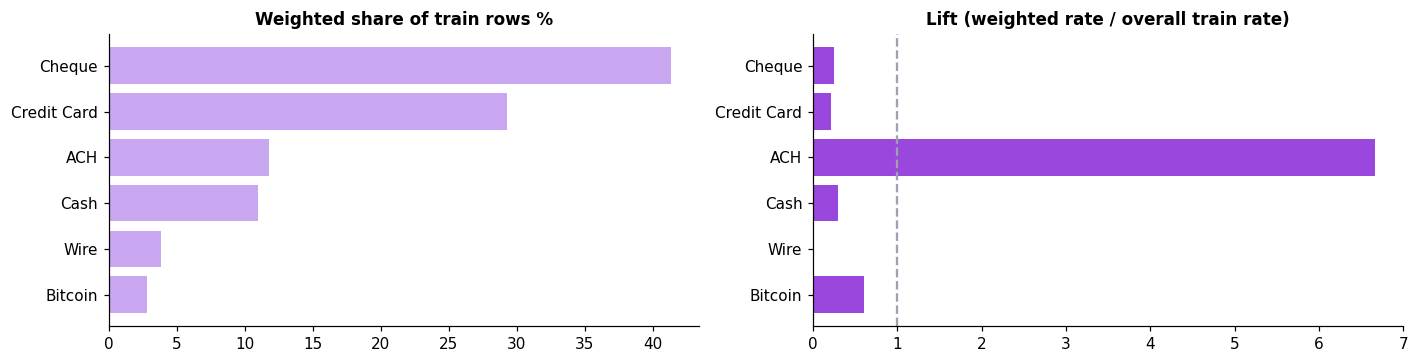

In [20]:
pf = wtab(TR["payment_format"], TR).sort_values("lift", ascending=False)
display(fmt_int(pf, ["rows", "laundering"]).round(4))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
p2 = pf.sort_values("weighted_share_pct")
ax[0].barh(p2["value"], p2["weighted_share_pct"], color=LILAC); ax[0].set_title("Weighted share of train rows %")
ax[1].barh(p2["value"], p2["lift"], color=PURPLE); ax[1].axvline(1, color=GREY, ls="--")
ax[1].set_title("Lift (weighted rate / overall train rate)")
plt.tight_layout(); plt.show()

**→ Rule.** `payment_format` is a feature (category). Because it can be this strong in the IBM simulator
(the generator writes most laundering steps as one format), it is also flagged as a **generator feature**:
04 trains with it, without it (`no_format`), and without all generator features (`no_generator`) to show
how much of the score depends on it.

## B9. Transfer flags: bank, border, owner, currency

**Question.** Does laundering go across banks, across borders, between different owners, or change
currency more than normal transfers do?

In [21]:
display(flag_lift(TR, ["cross_bank", "cross_border", "same_entity", "currency_changes"]).round(4))

,flag,laundering_rows_with_flag,weighted_share_pct,rate_when_1_pct,rate_when_0_pct,ratio
0,cross_border,1014,31.6664,0.1192,0.0531,2.2442
1,cross_bank,1960,97.5994,0.0748,0.0450,1.6624
2,same_entity,15,1.5268,0.0366,0.0746,0.4901
3,currency_changes,0,0.0634,0.0000,0.0741,0.0000


A flag with a ratio well below 1 still helps: it **clears** rows (e.g. same owner, or a currency change).
A flag that almost every row has (cross-bank) separates little on its own, but can still matter in
combination.

**→ Rule.** All four are features: `cross_bank` (compared by bank **name**, A6), `cross_border` (unknown
country counts as its own value), `same_entity`, `currency_changes`.

## B10. Categories: currency, country, owner type

**Question.** How many values does each category have in train, and how many have enough (weighted) volume
to learn a rate from?

In [22]:
MIN_W = 100                              # = CATEGORY_MIN_WEIGHT in 03
summ = []
for c in CATS:
    t_ = wtab(TR[c], TR)
    vol = TR.groupby(c)["w"].sum()
    summ.append({"category": c, "values_in_train": len(t_), f"values_with_weighted_volume_{MIN_W}+": int((vol >= MIN_W).sum()),
                 "weighted_share_of_rare_values_pct": 100 * vol[vol < MIN_W].sum() / vol.sum()})
display(pd.DataFrame(summ).round(3))
for c in ["payment_currency", "country_from", "etype_from"]:
    t_ = wtab(TR[c], TR, min_rows=0)
    t_ = t_.sort_values(["laundering", "lift"], ascending=False).head(8).sort_values("lift", ascending=False)
    print(f"\n{c}: the 8 values with the most laundering rows, by lift")
    display(fmt_int(t_.head(8), ["rows", "laundering"]).round(4))

,category,values_in_train,values_with_weighted_volume_100+,weighted_share_of_rare_values_pct
0,payment_format,6,6,0.000
1,payment_currency,15,15,0.000
2,country_from,33,30,0.005
3,country_to,31,31,0.000
4,etype_from,6,6,0.000
5,etype_to,6,5,0.001



payment_currency: the 8 values with the most laundering rows, by lift


,value,rows,laundering,weighted_share_pct,weighted_rate_pct,lift
8,Saudi Riyal,"7,978",121,1.6707,0.2697,3.6413
3,Canadian Dollar,"10,742",60,2.6360,0.0848,1.1444
4,Euro,"102,983",496,23.1209,0.0799,1.0786
6,Ruble,"12,731",63,3.0383,0.0772,1.0425
14,Yuan,"16,315",77,3.8456,0.0746,1.0067
12,US Dollar,"156,393",726,37.3309,0.0724,0.9778
7,Rupee,"14,953",72,3.8439,0.0697,0.9417
10,Swiss Franc,"18,688",77,4.7409,0.0605,0.8166



country_from: the 8 values with the most laundering rows, by lift


,value,rows,laundering,weighted_share_pct,weighted_rate_pct,lift
27,Saudi Arabia,"5,697",98,1.1761,0.3103,4.1895
30,Spain,"9,144",52,2.0666,0.0937,1.2651
9,Domestic/Other,"185,611","1,007",46.3775,0.0808,1.0917
17,Israel,"13,318",64,3.2647,0.0730,0.9856
12,France,"13,940",58,3.1092,0.0695,0.9379
5,China,"22,741",78,4.9879,0.0582,0.7862
31,Switzerland,"18,223",63,4.4166,0.0531,0.7172
13,Germany,"30,067",86,6.4791,0.0494,0.6673



etype_from: the 8 values with the most laundering rows, by lift


,value,rows,laundering,weighted_share_pct,weighted_rate_pct,lift
3,Individual,294,4,0.0687,0.2168,2.9269
0,Corporation,"119,049",767,27.4126,0.1042,1.4067
4,Partnership,"147,684",633,35.1846,0.0670,0.9045
5,Sole Proprietorship,"146,135",564,35.5674,0.0590,0.7972
1,Country,"6,266",21,1.7551,0.0446,0.6016
2,Direct,44,0,0.0116,0.0000,0.0000


**→ Rule.** Six categorical features (`payment_format`, `payment_currency`, `country_from`, `country_to`,
`etype_from`, `etype_to`). Levels are learned on train: a value needs **≥ 100 weighted train rows**,
otherwise it becomes `Other`. Values first seen in val/test become `Other` too.

## B11. Amount (in US Dollars)

**Question.** Is risk higher for larger amounts, and is the relationship a straight line?

,weighted_decile,rows,laundering,weighted_share_pct,weighted_rate_pct,lift,from_usd,to_usd
0,1,"41,514",38,10.0,0.0142,0.19,0.00,4.896000e+01
1,2,"41,535",44,10.0,0.0164,0.22,48.96,1.306300e+02
2,3,"41,689",79,10.0,0.0294,0.40,130.65,2.495000e+02
3,4,"41,652",97,10.0,0.0361,0.49,249.51,4.847300e+02
4,5,"42,002",117,10.0,0.0436,0.59,484.77,9.673700e+02
5,6,"41,967",212,10.0,0.0789,1.07,967.42,1.853020e+03
6,7,"42,435",351,10.0,0.1307,1.76,1853.08,3.555210e+03
7,8,"42,417",452,10.0,0.1683,2.27,3555.34,8.263350e+03
8,9,"42,178",501,10.0,0.1865,2.52,8263.59,2.870857e+04
9,10,"42,083",98,10.0,0.0365,0.49,28708.61,1.662061e+10


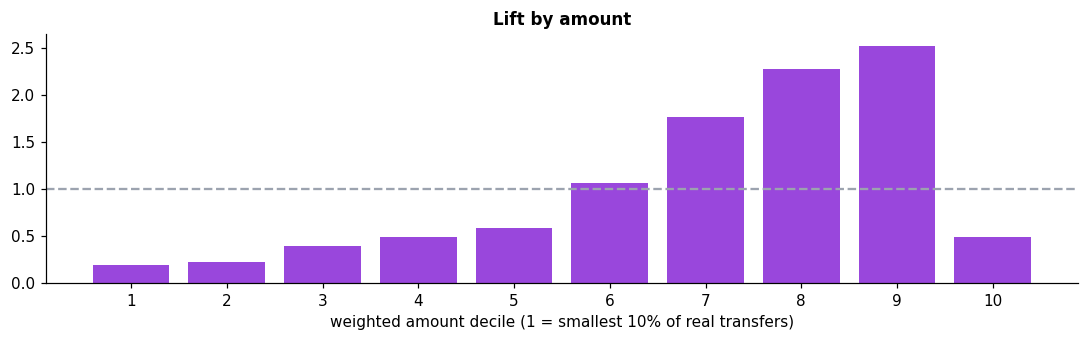

Weighted median USD - normal: 966.19 | laundering: 3831.93


In [23]:
v, w = TR["amount_usd"].to_numpy(), TR["w"].to_numpy()
ok = ~np.isnan(v)
o = np.argsort(v[ok], kind="stable")
cw = np.cumsum(w[ok][o]) / w[ok].sum()
edges = [v[ok][o][np.searchsorted(cw, qq)] for qq in np.linspace(0.1, 0.9, 9)]
dec = 1 + np.searchsorted(edges, v[ok], side="right")
at = wtab(dec, TR[ok], "weighted_decile")
lo_hi = pd.DataFrame({"weighted_decile": dec, "v": v[ok]}).groupby("weighted_decile")["v"].agg(from_usd="min", to_usd="max")
at = at.merge(lo_hi.reset_index(), on="weighted_decile")
display(fmt_int(at, ["rows", "laundering"]).round({"from_usd": 2, "to_usd": 2, "weighted_rate_pct": 4, "lift": 2,
                                                   "weighted_share_pct": 2}))
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(at["weighted_decile"].astype(str), at["lift"], color=PURPLE); ax.axhline(1, color=GREY, ls="--")
ax.set_xlabel("weighted amount decile (1 = smallest 10% of real transfers)"); ax.set_title("Lift by amount")
plt.tight_layout(); plt.show()
print("Weighted median USD - normal:", round(wmedian(v[ok][TR['y'].to_numpy()[ok] == 0], w[ok][TR['y'].to_numpy()[ok] == 0]), 2),
      "| laundering:", round(float(np.median(v[ok][TR['y'].to_numpy()[ok] == 1])), 2))

**→ Rule.** One amount feature, `log_amount_usd = ln(1 + amount in USD)`, with one fixed rate per currency
(A7; 03 learns the table from the train split). If the lift is not monotone, trees handle it as is; the
logistic regression in 04 gets amount buckets instead.

## B12. How active the accounts were in the last 48 hours

**Question.** Before a transfer, how many transfers had the sender and the receiver made, and with how many
different accounts? (Rows with 48 h of history only.)

In [24]:
E = [("0", 0), ("1-2", 2), ("3-10", 10), ("11-50", 50), ("51-200", 200)]
for col in ["snd_sent_48h", "rcv_recv_48h", "snd_cpty_48h", "rcv_cpty_48h"]:
    print(col)
    display(fmt_int(bucket_table(TRH, col, E), ["rows", "laundering"]).round(4).set_index("bucket").T)

med = pd.DataFrame({
    "normal (weighted median)": [wmedian(TRH.loc[TRH["y"] == 0, c], TRH.loc[TRH["y"] == 0, "w"]) for c in COUNTS],
    "laundering (median)": [TRH.loc[TRH["y"] == 1, c].median() for c in COUNTS],
    "weighted 99.9th pct": [(lambda v_, w_: np.asarray(v_)[np.argsort(v_, kind="stable")][np.searchsorted(
        np.cumsum(np.asarray(w_)[np.argsort(v_, kind="stable")]), 0.999 * np.sum(w_))])(TRH[c].to_numpy(), TRH["w"].to_numpy())
        for c in COUNTS],
    "max": [TRH[c].max() for c in COUNTS]}, index=COUNTS)
display(med)

snd_sent_48h


bucket,0,1-2,3-10,11-50,51-200,over 200
rows,"14,593","26,925","94,029","61,148",126,"14,594"
laundering,602,138,284,59,0,194
weighted_share_pct,5.8577,12.6672,44.183,26.9605,0.0493,10.2823
weighted_rate_pct,0.7642,0.081,0.0478,0.0163,0.0,0.1403
lift,8.0479,0.8531,0.5034,0.1714,0.0,1.4775


rcv_recv_48h


bucket,0,1-2,3-10,11-50,51-200
rows,"15,917","45,065","139,457","10,784",192
laundering,332,290,561,92,2
weighted_share_pct,7.4731,21.569,66.2814,4.6116,0.0649
weighted_rate_pct,0.3304,0.1,0.0629,0.1484,0.2292
lift,3.4789,1.0529,0.6628,1.5622,2.4133


snd_cpty_48h


bucket,0,1-2,3-10,11-50,51-200,over 200
rows,"14,593","103,073","77,230","1,925",44,"14,550"
laundering,602,319,150,12,0,194
weighted_share_pct,5.8577,48.456,34.6388,0.7652,0.0336,10.2488
weighted_rate_pct,0.7642,0.049,0.0322,0.1166,0.0,0.1408
lift,8.0479,0.5155,0.3391,1.228,0.0,1.4823


rcv_cpty_48h


bucket,0,1-2,3-10,11-50,51-200
rows,"15,917","175,931","17,141","2,234",192
laundering,332,665,243,35,2
weighted_share_pct,7.4731,84.2687,7.495,0.6983,0.0649
weighted_rate_pct,0.3304,0.0587,0.2411,0.3727,0.2292
lift,3.4789,0.618,2.5389,3.9251,2.4133


,normal (weighted median),laundering (median),weighted 99.9th pct,max
snd_sent_48h,8,1.0,44690,49166
snd_recv_48h,2,1.0,543,545
rcv_recv_48h,4,3.0,45,80
rcv_sent_48h,0,0.0,35,57
snd_cpty_48h,2,1.0,13255,14230
rcv_cpty_48h,1,1.0,45,80
pair_prev_48h,3,0.0,14,14
snd_sent_24h,4,0.0,22706,26365
snd_sent_60m,1,0.0,841,1033
rcv_recv_24h,2,1.0,45,80


**→ Rule.** Seven 48-hour count features: sent and received for both sides, distinct counterparties for both
sides, and earlier transfers of the same pair. The window is fixed at 48 h (not "since 1 Sept"), so a
value means the same on every day. Every count is **capped at its weighted train 99.9th percentile**, so a
handful of extreme accounts cannot dominate. Counts only use transfers at strictly earlier timestamps.

## B13. Bursts: the last hour and the last day

**Question.** Does laundering come in bursts, i.e. many transfers within an hour or a day?

In [25]:
E2 = [("0", 0), ("1", 1), ("2-3", 3), ("4-10", 10), ("11-50", 50)]
for col in ["snd_sent_60m", "rcv_recv_60m", "snd_sent_24h", "rcv_recv_24h"]:
    print(col)
    display(fmt_int(bucket_table(TRH, col, E2), ["rows", "laundering"]).round(4).set_index("bucket").T)

snd_sent_60m


bucket,0,1,2-3,4-10,11-50,over 50
rows,"97,047","65,205","30,674","3,949","2,633","11,907"
laundering,"1,044",29,9,2,29,164
weighted_share_pct,44.0079,30.0137,14.0003,1.7382,1.8844,8.3556
weighted_rate_pct,0.1764,0.0072,0.0048,0.0086,0.1144,0.146
lift,1.8577,0.0757,0.0503,0.0901,1.2051,1.537


rcv_recv_60m


bucket,0,1,2-3,4-10,11-50,over 50
rows,"101,984","74,685","28,741","3,654","2,161",190
laundering,936,172,86,53,28,2
weighted_share_pct,48.9167,35.5241,13.3775,1.4437,0.6732,0.0647
weighted_rate_pct,0.1423,0.036,0.0478,0.273,0.3093,0.2297
lift,1.4984,0.3792,0.5034,2.8747,3.2569,2.4188


snd_sent_24h


bucket,0,1,2-3,4-10,11-50,over 50
rows,"31,503","25,448","47,495","72,346","20,029","14,594"
laundering,703,89,167,111,13,194
weighted_share_pct,13.8034,12.0385,22.2738,33.2656,8.3364,10.2823
weighted_rate_pct,0.3787,0.055,0.0558,0.0248,0.0116,0.1403
lift,3.9882,0.5789,0.5871,0.2613,0.1221,1.4775


rcv_recv_24h


bucket,0,1,2-3,4-10,11-50,over 50
rows,"45,722","43,823","73,067","46,012","2,599",192
laundering,489,195,300,256,35,2
weighted_share_pct,21.8656,21.0018,34.8188,21.3831,0.8658,0.0649
weighted_rate_pct,0.1663,0.069,0.0641,0.089,0.3006,0.2292
lift,1.7513,0.7271,0.6747,0.9375,3.1657,2.4133


**→ Rule.** Four burst counts: sender sent and receiver received, over the last 60 minutes and the last
24 hours. They are capped like the 48 h counts.

## B14. New and two-way pairs, quiet accounts

**Question.** Is a first-time sender→receiver pair riskier? A pair where the receiver had also paid the
sender? An account that was completely quiet for 48 hours?

In [26]:
display(flag_lift(TRH, ["new_pair_48h", "reverse_pair_48h", "snd_quiet_48h", "rcv_quiet_48h"]).round(4))
print("pair_prev_48h")
display(fmt_int(bucket_table(TRH, "pair_prev_48h", [("0", 0), ("1", 1), ("2-5", 5), ("6-20", 20)]),
                ["rows", "laundering"]).round(4).set_index("bucket").T)

,flag,laundering_rows_with_flag,weighted_share_pct,rate_when_1_pct,rate_when_0_pct,ratio
0,reverse_pair_48h,77,0.0697,8.2210,0.0893,92.0617
1,new_pair_48h,1011,16.3886,0.4587,0.0237,19.3906
2,snd_quiet_48h,319,3.2266,0.7352,0.0736,9.9871
3,rcv_quiet_48h,234,5.0285,0.3461,0.0817,4.2373


pair_prev_48h


bucket,0,1,2-5,6-20
rows,"36,751","24,563","123,032","27,069"
laundering,"1,011",73,177,16
weighted_share_pct,16.3886,11.9194,58.838,12.854
weighted_rate_pct,0.4587,0.0455,0.0224,0.0093
lift,4.8308,0.4796,0.2356,0.0975


**→ Rule.** Four flags: `new_pair_48h`, `reverse_pair_48h`, `snd_quiet_48h`, `rcv_quiet_48h`.

## B15. Money in, money out: pass-through, dwell time, conversion

**Question.**
- **Pass-through:** does the sender forward, within 24 h, roughly what it just received (within 10%)?
- **Dwell:** how long does money sit before it moves on?
- **Conversion:** was this payment preceded, in the same minute, by the sender converting the same amount
  into this currency (a self-transfer)?

In [27]:
display(flag_lift(TRH, ["passthrough", "conversion_before"]).round(4))
dw = TRH.assign(dwell_bucket=buckets(TRH["snd_dwell_h"], [("under 1 h", 0.999), ("1-6 h", 6), ("6-23.9 h", 23.99)]))
dw["dwell_bucket"] = dw["dwell_bucket"].replace({"over 23.99": "24 h+ or never"})
display(fmt_int(wtab(dw["dwell_bucket"], dw), ["rows", "laundering"]).round(4))
print("Weighted median dwell (h) - normal:",
      round(wmedian(TRH.loc[TRH['y'] == 0, 'snd_dwell_h'], TRH.loc[TRH['y'] == 0, 'w']), 2),
      "| laundering:", round(TRH.loc[TRH['y'] == 1, 'snd_dwell_h'].median(), 2))

,flag,laundering_rows_with_flag,weighted_share_pct,rate_when_1_pct,rate_when_0_pct,ratio
0,conversion_before,279,1.5549,1.3343,0.0754,17.6997
1,passthrough,58,1.2184,0.3540,0.0918,3.8575


,value,rows,laundering,weighted_share_pct,weighted_rate_pct,lift
0,1-6 h,"29,679",130,13.6137,0.0710,0.7478
1,24 h+ or never,"104,371",816,50.7076,0.1197,1.2602
2,6-23.9 h,"70,358",306,32.4764,0.0701,0.7378
3,under 1 h,"7,007",25,3.2022,0.0581,0.6114


Weighted median dwell (h) - normal: 24.0 | laundering: 24.0


**→ Rule.** Features: `passthrough` (flag), `snd_dwell_h` (hours since the sender last received from
another account, capped at 24), `conversion_before` (flag).

`conversion_before` is how the IBM generator writes a currency conversion step, so it may be much weaker on
real bank data. It is a **generator feature** (see B8) and is dropped in the `no_generator` model.

## B16. Hub accounts

**Question.** Does it matter whether the sender or receiver is a hub (500+ counterparties on train dates)?

In [28]:
display(flag_lift(TR, ["snd_hub", "rcv_hub"]).round(4))
print(f"Hubs (from the full-file history on train dates): {int((cp_ >= 500).sum())}")

,flag,laundering_rows_with_flag,weighted_share_pct,rate_when_1_pct,rate_when_0_pct,ratio
0,snd_hub,390,9.9429,0.1461,0.0661,2.2091
1,rcv_hub,0,0.0635,0.0000,0.0741,0.0000


Hubs (from the full-file history on train dates): 15


**→ Rule.** Two flags, `snd_hub` and `rcv_hub`. The hub list is learned on train dates (full-file
history) and saved in `artifacts.json`.

## B16b. Graph shape and sender behaviour (multi-hop features)

**Question.** Laundering schemes are *shapes*: money fans out, gathers, passes through a middle account
or comes back in a cycle. The features so far see one step (sender, receiver, the pair). Do features
that see **two steps** separate laundering better? All point-in-time over [t − window, t), full-file
history, same definitions as `03_PREPROCESSING`:

| Feature | Meaning | Scheme shape |
|---|---|---|
| `snd_cpty_6h`, `rcv_cpty_6h` | distinct receivers / senders in the last 6 h | fan-out / fan-in burst |
| `snd_in_cpty_48h` | distinct accounts that paid the sender | gather side |
| `rcv_out_cpty_48h` | distinct accounts the receiver paid | scatter side |
| `sg_paths_48h` | accounts x with sender → x and x → receiver | scatter-gather, bipartite |
| `cycle3_48h` | accounts x with receiver → x and x → sender | cycle |
| `snd_recv_usd_24h` | ln(1 + USD the sender received in 24 h) | layering / pass-through |
| `snd_amt_vs_mean_48h` | this amount vs the sender's mean (log ratio) | unusual for this sender |
| `snd_new_format_48h` | sender uses a payment format it has not used in 48 h | (uses the format: generator set) |

In [29]:
from sklearn.metrics import average_precision_score


def window_neighbors(owner, other, ev_t, q_owner, q_t, window):
    """(query index, neighbour) for every event of q_owner in [t - window, t)."""
    o = np.lexsort((ev_t, owner))
    k, nb = keyed(np.asarray(owner)[o], np.asarray(ev_t)[o]), np.asarray(other, np.int64)[o]
    lo = np.searchsorted(k, keyed(q_owner, np.maximum(np.asarray(q_t) - window, 0)), "left")
    hi = np.searchsorted(k, keyed(q_owner, np.maximum(q_t, 0)), "left")
    n = hi - lo
    pos = np.repeat(lo - np.r_[0, np.cumsum(n)[:-1]], n) + np.arange(int(n.sum()))
    return np.repeat(np.arange(len(n)), n), nb[pos]


def two_hop(mid_owner, mid_other, q_mid, q_end, q_t, window):
    """Per query: distinct x linked to q_mid (events mid_owner -> mid_other, x = mid_other) in the window
    such that q_end -> x also happened in the window."""
    qi, x = window_neighbors(mid_owner, mid_other, ht, q_mid, q_t, window)
    u = np.unique(qi.astype(np.int64) * N_ACCT + x)
    qi, x = u // N_ACCT, u % N_ACCT
    pk, tq = np.asarray(q_end, np.int64)[qi] * N_ACCT + x, np.asarray(q_t, np.int64)[qi]
    hit = (np.searchsorted(PKS, keyed(pk, tq), "left") - np.searchsorted(PKS, keyed(pk, np.maximum(tq - window, 0)), "left")) > 0
    return np.bincount(qi[hit], minlength=len(q_t))


def sum_in_window(ev_id, ev_t, vals, q_id, lo, hi):
    o = np.lexsort((ev_t, ev_id))
    ids, k = np.asarray(ev_id, np.int64)[o], keyed(np.asarray(ev_id)[o], np.asarray(ev_t)[o])
    cs = pd.Series(np.asarray(vals, float)[o]).groupby(ids).cumsum().to_numpy()
    q_id = np.asarray(q_id, np.int64)
    before = lambda i: np.where((i - 1 >= 0) & (ids[np.maximum(i - 1, 0)] == q_id), cs[np.maximum(i - 1, 0)], 0.0)
    return before(np.searchsorted(k, keyed(q_id, np.maximum(hi, 0)), "left")) - \
        before(np.searchsorted(k, keyed(q_id, np.maximum(lo, 0)), "left"))


H6 = 6 * 3600
PKS = np.sort(keyed(ha * N_ACCT + hb, ht))
F["snd_cpty_6h"] = distinct_in_window(ha, hb, ht, a, t, H6)
F["rcv_cpty_6h"] = distinct_in_window(hb, ha, ht, b, t, H6)
F["snd_in_cpty_48h"] = distinct_in_window(hb, ha, ht, a, t, H48)
F["rcv_out_cpty_48h"] = distinct_in_window(ha, hb, ht, b, t, H48)
F["sg_paths_48h"] = two_hop(hb, ha, b, a, t, H48)            # x -> receiver, and sender -> x
F["cycle3_48h"] = two_hop(hb, ha, a, b, t, H48)              # x -> sender, and receiver -> x
prate = np.array([FX.get(c, np.nan) for c in j["Payment Currency"].cat.categories])
usd_out = PAID[HB] / prate[j["Payment Currency"].cat.codes.to_numpy()[HB]]
F["snd_recv_usd_24h"] = np.log1p(sum_in_window(hb, ht, usd_in, a, t - H24, t))
n_sent = F["snd_sent_48h"].to_numpy()
with np.errstate(divide="ignore", invalid="ignore"):
    F["snd_amt_vs_mean_48h"] = np.where(n_sent > 0, np.log1p(F["amount_usd"]) - np.log1p(sum_in_window(ha, ht, usd_out, a, t - H48, t) / n_sent), 0.0)
fcode = j["Payment Format"].cat.codes.to_numpy().astype(np.int64)
qf = to_codes(s["Payment Format"], j["Payment Format"].cat.categories)[q]
F["snd_new_format_48h"] = ((n_sent > 0) & (count_in_window(ha * 16 + fcode[HB], ht, a * 16 + qf, t - H48, t) == 0)).astype(int)
del PKS

NEW = ["snd_cpty_6h", "rcv_cpty_6h", "snd_in_cpty_48h", "rcv_out_cpty_48h", "sg_paths_48h", "cycle3_48h",
       "snd_recv_usd_24h", "snd_amt_vs_mean_48h", "snd_new_format_48h"]
TR = F[(F["split"] == "train") & F["reach"]].reset_index(drop=True)
TRH = TR[TR["hc"]].reset_index(drop=True)
present = TRH.assign(**{f"{c}>0": (TRH[c] != 0).astype(int) for c in NEW})
display(flag_lift(present, [f"{c}>0" for c in NEW]).round(4))
yv, wv = TRH["y"].to_numpy(), TRH["w"].to_numpy()
ap_new = pd.DataFrame([(c, max(average_precision_score(yv, TRH[c], sample_weight=wv),
                               average_precision_score(yv, -TRH[c], sample_weight=wv)) / ((wv * yv).sum() / wv.sum()))
                       for c in NEW], columns=["feature", "AP_x_base_rate"]).sort_values("AP_x_base_rate", ascending=False)
display(ap_new.round(2).reset_index(drop=True))
print("sg_paths_48h"); display(fmt_int(bucket_table(TRH, "sg_paths_48h", [("0", 0), ("1", 1), ("2-5", 5)]), ["rows", "laundering"]).round(4).set_index("bucket").T)

,flag,laundering_rows_with_flag,weighted_share_pct,rate_when_1_pct,rate_when_0_pct,ratio
0,cycle3_48h>0,22,0.0036,45.2338,0.0933,484.6673
1,sg_paths_48h>0,34,0.4971,0.5086,0.0929,5.4748
2,snd_new_format_48h>0,142,6.5680,0.1608,0.0903,1.7797
3,rcv_out_cpty_48h>0,525,41.1497,0.0949,0.0950,0.9984
4,snd_in_cpty_48h>0,673,63.1697,0.0792,0.1220,0.6496
5,snd_recv_usd_24h>0,461,49.3144,0.0695,0.1197,0.5807
6,rcv_cpty_6h>0,493,55.5503,0.0660,0.1312,0.5032
7,snd_cpty_6h>0,346,65.9856,0.0390,0.2035,0.1916
8,snd_amt_vs_mean_48h>0,675,93.1654,0.0539,0.6550,0.0823


,feature,AP_x_base_rate
0,cycle3_48h,11.45
1,sg_paths_48h,1.97
2,snd_cpty_6h,1.84
3,snd_amt_vs_mean_48h,1.65
4,rcv_cpty_6h,1.31
5,snd_recv_usd_24h,1.18
6,snd_in_cpty_48h,1.12
7,snd_new_format_48h,1.08
8,rcv_out_cpty_48h,1.00


sg_paths_48h


bucket,0,1,2-5
rows,"210,533",869,13
laundering,"1,243",27,7
weighted_share_pct,99.5029,0.4937,0.0034
weighted_rate_pct,0.0929,0.4067,15.3083
lift,0.9782,4.2823,161.2036


Read the ratio column for "how much riskier when present" and AP × base rate for "how well it ranks on
its own". The path and cycle features are rare, but when they fire they point at the scheme shapes the
one-step features cannot see.

**→ Rule.** Nine more features (40 in total): six graph-shape counts (capped like the other counts) and
three sender-behaviour features. `snd_new_format_48h` uses the payment format, so it joins the
**format / generator** feature sets and is dropped in `no_format` / `no_generator`.

## B17. All signals side by side, and overlaps

**Question.** On its own, how well does each feature rank laundering above normal (weighted average
precision; a useless feature scores the base rate)? Which counts carry the same information?

In [30]:
from sklearn.metrics import average_precision_score

yv, wv = TRH["y"].to_numpy(), TRH["w"].to_numpy()
base_ap = (wv * yv).sum() / wv.sum()
rank = []
for c in COUNTS + NEW + ["snd_dwell_h", "log_amount_usd"] + FLAGS:
    x = TRH[c].fillna(0).to_numpy(float)
    up = average_precision_score(yv, x, sample_weight=wv)
    down = average_precision_score(yv, -x, sample_weight=wv)
    rank.append((c, max(up, down), "higher = riskier" if up >= down else "lower = riskier"))
rank = pd.DataFrame(rank, columns=["feature", "weighted_AP", "direction"]).sort_values("weighted_AP", ascending=False)
rank["x_base_rate"] = rank["weighted_AP"] / base_ap
print(f"Base rate (AP of a useless feature): {base_ap:.6f}")
display(rank.round(6).reset_index(drop=True))

corr = TRH[COUNTS].sample(min(len(TRH), 200_000), random_state=0).corr(method="spearman")
pairs = [(x, y_, corr.loc[x, y_]) for i, x in enumerate(COUNTS) for y_ in COUNTS[i + 1:] if abs(corr.loc[x, y_]) > 0.85]
print("Count pairs with |Spearman| > 0.85:")
display(pd.DataFrame(pairs, columns=["feature_a", "feature_b", "spearman"]).round(3))

Base rate (AP of a useless feature): 0.000950


,feature,weighted_AP,direction,x_base_rate
0,cycle3_48h,0.010870,higher = riskier,11.447094
1,reverse_pair_48h,0.005849,higher = riskier,6.159715
2,snd_sent_48h,0.004602,lower = riskier,4.846390
3,snd_cpty_48h,0.004278,lower = riskier,4.504874
4,pair_prev_48h,0.004008,lower = riskier,4.220317
5,new_pair_48h,0.003830,higher = riskier,4.032828
6,conversion_before,0.003657,higher = riskier,3.851415
7,log_amount_usd,0.003581,higher = riskier,3.771189
8,snd_sent_24h,0.002720,lower = riskier,2.864599
9,snd_quiet_48h,0.002549,higher = riskier,2.684194


Count pairs with |Spearman| > 0.85:


,feature_a,feature_b,spearman
0,snd_sent_48h,snd_cpty_48h,0.891
1,snd_sent_48h,snd_sent_24h,0.884


No single feature is close to good enough. The model has to combine them.

**→ Rule.** Keep all of them (the new B16b features included) for the tree model (it copes with overlap). The logistic regression in 04 drops
one feature of each pair with |correlation| > 0.85. Single-feature AP is a ranking aid, not a reason to
drop a feature.

## B17b. Signals tested and not built

**Question.** A few more ideas: time of day, round amounts, "minutes since the sender's last transfer", and
country-to-country routes. Do they add anything on the train split?

In [31]:
hr = wtab(TR["hour"], TR, "hour")
print(f"Hour of day: lift ranges from {hr['lift'].min():.2f} to {hr['lift'].max():.2f}; "
      f"hour 0 holds {hr.loc[hr['hour'] == 0, 'weighted_share_pct'].sum():.1f}% of weighted rows (booking bucket)")
display(fmt_int(hr.sort_values("lift", ascending=False).head(5), ["rows", "laundering"]).round(4))
print("Calendar: 1-10 Sept has each weekday once or twice, so a weekday feature would learn individual days.")

rd = TR.assign(round_100=(np.fmod(TR["paid"], 100) == 0).astype(int), whole=(np.fmod(TR["paid"], 1) == 0).astype(int))
display(flag_lift(rd, ["round_100", "whole"]).round(4))

g_ = TRH.dropna(subset=["gap_min"])
ap_gap = max(average_precision_score(g_["y"], g_["gap_min"], sample_weight=g_["w"]),
             average_precision_score(g_["y"], -g_["gap_min"], sample_weight=g_["w"]))
rho = g_[["gap_min", "snd_sent_48h"]].corr(method="spearman").iloc[0, 1]
print(f"Minutes since the sender's last transfer: weighted AP {ap_gap:.5f} (base {(g_['w'] * g_['y']).sum() / g_['w'].sum():.5f}); "
      f"Spearman with snd_sent_48h: {rho:.2f}")

rt = wtab(TR["route"], TR, "route")
print(f"Country routes in train: {len(rt)} | with 20+ laundering rows: {(rt['laundering'] >= 20).sum()} | "
      f"with fewer than 5: {(rt['laundering'] < 5).sum()}")

Hour of day: lift ranges from 0.50 to 1.44; hour 0 holds 9.6% of weighted rows (booking bucket)


,hour,rows,laundering,weighted_share_pct,weighted_rate_pct,lift
16,16,"16,417",113,3.9506,0.1065,1.4381
13,13,"16,430",106,3.8902,0.1015,1.3699
8,8,"16,668",106,3.9148,0.1008,1.3613
14,14,"16,607",104,3.9629,0.0977,1.3194
17,17,"16,500",101,3.8998,0.0964,1.3021


Calendar: 1-10 Sept has each weekday once or twice, so a weekday feature would learn individual days.


,flag,laundering_rows_with_flag,weighted_share_pct,rate_when_1_pct,rate_when_0_pct,ratio
0,round_100,1,0.0176,0.2113,0.0740,2.8539
1,whole,26,1.4571,0.0664,0.0742,0.8958


Minutes since the sender's last transfer: weighted AP 0.00242 (base 0.00061); Spearman with snd_sent_48h: -0.49
Country routes in train: 565 | with 20+ laundering rows: 17 | with fewer than 5: 500


**→ Rule.** Not built:
- **Hour / weekday.** Hour 0 is a booking bucket and ten days cannot teach a weekly pattern.
- **Round / whole amounts.** No structuring signal worth a feature in this generator (compare the ratios
  above).
- **Minutes since the last transfer.** Strongly tied to how busy the sender is, which the 48 h counts
  already capture.
- **Country routes.** Most routes rest on a handful of laundering rows, which is noise. `country_from` and
  `country_to` cover the useful part.
- **Account lifetime / active span.** It needs the account's *future* transfers, so it would leak.

Also out: `Amount Received` (same as `Amount Paid` unless the currency changes, and that case is
`currency_changes`).

## B18. Do the signals hold from day to day?

**Question.** A signal that is strong one day and gone the next will not survive the test days. Weighted
ratio per day for the main flags, on **train and val days only** (test stays unseen).

,day,rows,laundering,reverse_pair_48h,new_pair_48h,conversion_before,snd_quiet_48h,passthrough,cross_border,cross_bank,same_entity
0,03 Sept,31945,366,48.47,37.39,24.62,8.71,4.65,2.38,0.78,0.51
1,04 Sept,31880,349,47.65,48.67,27.13,11.63,9.02,2.38,4.15,0.00
2,05 Sept,73808,332,127.57,6.74,19.55,6.92,3.03,2.40,1.39,0.90
3,06 Sept,73876,324,158.44,59.15,13.31,27.35,2.25,2.14,1.36,0.69
4,07 Sept,73754,229,130.24,29.44,7.32,14.99,2.91,2.11,0.82,0.31


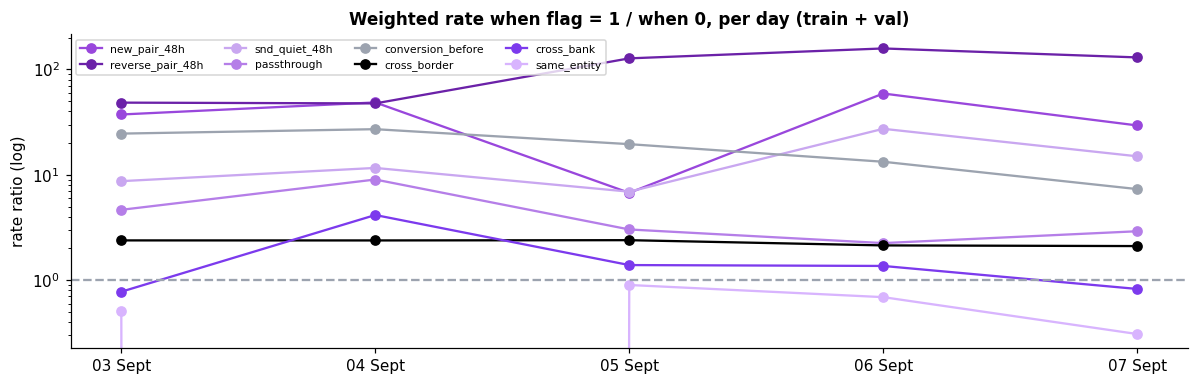

In [32]:
STAB = ["new_pair_48h", "reverse_pair_48h", "snd_quiet_48h", "passthrough", "conversion_before",
        "cross_border", "cross_bank", "same_entity"]
FV = F[F["split"].isin(["train", "val"]) & F["reach"] & F["hc"]]
rows = []
for day_, d in FV.groupby("day"):
    fl = flag_lift(d, STAB).set_index("flag")["ratio"]
    rows.append({"day": pd.Timestamp(day_).strftime("%d Sept"), "rows": len(d), "laundering": int(d["y"].sum()), **fl.to_dict()})
stab = pd.DataFrame(rows)
display(stab.round(2))
fig, ax = plt.subplots(figsize=(11, 3.6))
for f_, colour in zip(STAB, [PURPLE, DARK, LILAC, "#b57ee8", GREY, "black", "#7c3aed", "#d8b4fe"]):
    ax.plot(stab["day"], stab[f_].clip(upper=200), marker="o", label=f_, color=colour)
ax.set_yscale("log"); ax.axhline(1, color=GREY, ls="--"); ax.set_ylabel("rate ratio (log)")
ax.legend(ncol=4, fontsize=7); ax.set_title("Weighted rate when flag = 1 / when 0, per day (train + val)")
plt.tight_layout(); plt.show()

Days with few laundering rows give noisy ratios. Look for the sign (above or below 1) staying the same, not
the exact size.

**→ Rule.** Fixed definitions for every day: one 48 h window, one FX table, one hub list, all learned on
train. Nothing is re-fitted per day. Drift on val/test is measured in 03 (PSI, §6.1) and 04 (fixed
threshold vs daily top-k).

## B19. Rules handed to preprocessing

| # | Rule | From |
|---|---|---|
| 1 | Drop rows from 11 Sept on (leftover scheme rows) | A3 |
| 2 | Self-transfer = same bank AND same account. Not scored; never counted as history | A5 |
| 3 | `Attempt ID`, `Pattern Type` = ground truth for evaluation only | A4, B3 |
| 4 | Bank compared by **name**, not ID | A6 |
| 5 | One fixed USD rate per currency, learned on train | A7, B11 |
| 6 | Hub = 500+ distinct counterparties on train dates | A8, B16 |
| 7 | All checks of B1 pass, rows matched 1:1 to the full file | B1 |
| 8 | `weight` in every learned number and every metric | B2 |
| 9 | Never a feature: sampler columns, `accounts.parquet`, IDs and names (`leak_columns`) | B3 |
| 10 | Train / val / test by date, schemes whole; test metrics on own date; group split as a check | B4 |
| 11 | Rows with no seed side: kept, but out of fitting and metrics | B5 |
| 12 | Account history from the **full file**, strictly earlier timestamps | B6 |
| 13 | Rows without 48 h of history out of fitting | B7 |
| 14 | 40 features: 17 counts, 3 continuous, 13 flags, amount, 6 categories; hour, round amounts, gaps, routes, account span not built | B8–B17b |
| 15 | Counts capped at the weighted train 99.9th percentile; categories need 100 weighted train rows | B10, B12 |
| 16 | `payment_format`, `snd_new_format_48h`, `conversion_before` = generator features: models with and without them | B8, B15, B16b |
| 17 | Logistic regression drops one of each count pair with |corr| > 0.85 | B17 |

`notebooks/03_PREPROCESSING.ipynb` implements rules 1–16 and checks them (15 checks in the notebook, 58 in
`src/03b_verify_preprocessing.py`). Rule 17 lives in `04_MODELLING`.

In [33]:
del F, TR, TRH, FV, s
import gc; gc.collect()
print("EDA done.")

EDA done.
